**THES H6011 Research Thesis**

# Evaluation of Fairness and Explainability and Development of a Risk Assessment Agent for AI Based Fraud Detection Systems 

**2nd September 2026**

**Name:** Dhakshayini D. Janardhan
**Studen Id:** A00046733

**Environment Setup and Library Imports**

In [4]:
import sys
print(sys.executable)

import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt
import seaborn as sns

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("torch:", torch.__version__)
print("shap:", shap.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("All imports successful")

/opt/anaconda3/envs/thesis_env/bin/python
numpy: 1.24.3
pandas: 2.2.2
torch: 2.13.0
shap: 0.44.1
MPS available: True
All imports successful


**loading and exploring dataset**

In [5]:
base_df = pd.read_csv('Base.csv')
print("Shape:", base_df.shape)
print("Info:", base_df.info)
print("Null Info:", base_df.isnull().sum())
print("Basic Statistics:", base_df.describe())
print("Coulmns info:", base_df.columns.tolist())
print("Columns Datatypes:", base_df.dtypes)
print("First 5 rows:", base_df.head())

Shape: (1000000, 32)
Info: <bound method DataFrame.info of         fraud_bool  income  name_email_similarity  prev_address_months_count  \
0                0     0.3               0.986506                         -1   
1                0     0.8               0.617426                         -1   
2                0     0.8               0.996707                          9   
3                0     0.6               0.475100                         11   
4                0     0.9               0.842307                         -1   
...            ...     ...                    ...                        ...   
999995           0     0.8               0.124690                         -1   
999996           0     0.9               0.824544                         -1   
999997           0     0.8               0.140891                         -1   
999998           0     0.9               0.002480                         52   
999999           0     0.6               0.993391            

**Base Dataset Age Group Distribution**

In [6]:
total_base = len(base_df)

base_under50 = (base_df['customer_age'] < 50).sum()
base_50plus = (base_df['customer_age'] >= 50).sum()

print("BASE DATASET")
print("=" * 50)

print("Total applications:", total_base)

print("\nAge < 50:")
print("Applications:", base_under50)
print("Percentage:", round(base_under50 / total_base * 100, 2), "%")

print("\nAge >= 50:")
print("Applications:", base_50plus)
print("Percentage:", round(base_50plus / total_base * 100, 2), "%")

BASE DATASET
Total applications: 1000000

Age < 50:
Applications: 816987
Percentage: 81.7 %

Age >= 50:
Applications: 183013
Percentage: 18.3 %


**Fraud Class Distribution and Imbalance**

fraud_bool
0    988971
1     11029
Name: count, dtype: int64

Fraud percentage: 1.1 %


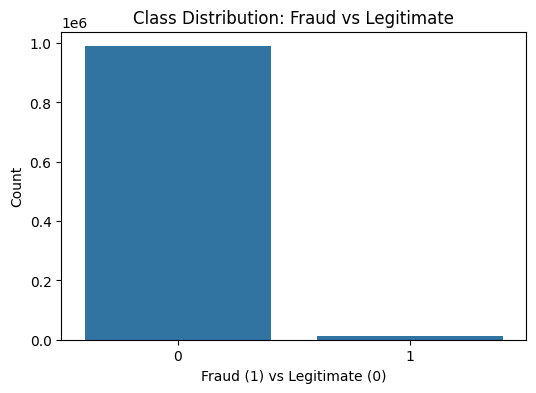

In [7]:
# Check Class Imbalance

# Fraud distribution
fraud_counts = base_df['fraud_bool'].value_counts()
print(fraud_counts)
print("\nFraud percentage:", 
      round(base_df['fraud_bool'].mean() * 100, 2), "%")

# Visualise
plt.figure(figsize=(6,4))
sns.countplot(x='fraud_bool', data=base_df)
plt.title('Class Distribution: Fraud vs Legitimate')
plt.xlabel('Fraud (1) vs Legitimate (0)')
plt.ylabel('Count')
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Base Dataset Age Group Distribution**

In [24]:
# ==========================================
# BASE DATASET - AGE GROUP DISTRIBUTION
# ==========================================

total_base = len(base_df)

base_under50 = (base_df['customer_age'] < 50).sum()
base_50plus = (base_df['customer_age'] >= 50).sum()

print("BASE DATASET")
print("=" * 50)

print("Total applications:", total_base)

print("\nAge < 50:")
print("Applications:", base_under50)
print("Percentage:", round(base_under50 / total_base * 100, 2), "%")

print("\nAge >= 50:")
print("Applications:", base_50plus)
print("Percentage:", round(base_50plus / total_base * 100, 2), "%")

BASE DATASET
Total applications: 1000000

Age < 50:
Applications: 816987
Percentage: 81.7 %

Age >= 50:
Applications: 183013
Percentage: 18.3 %


**Protected Attribute Distribution Analysis**

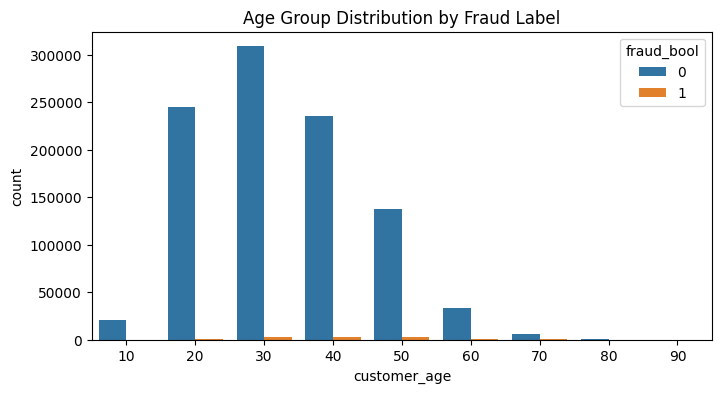

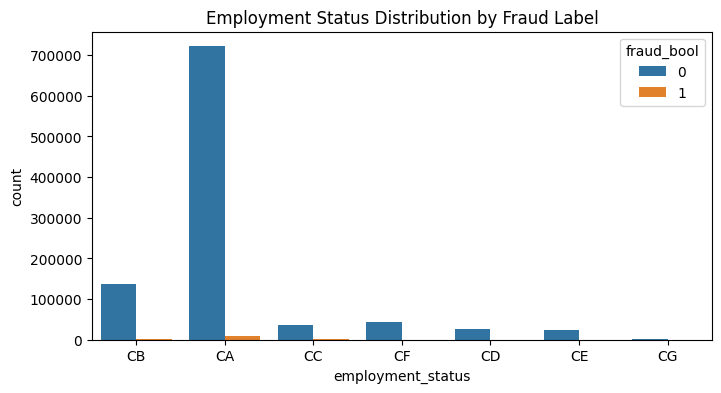

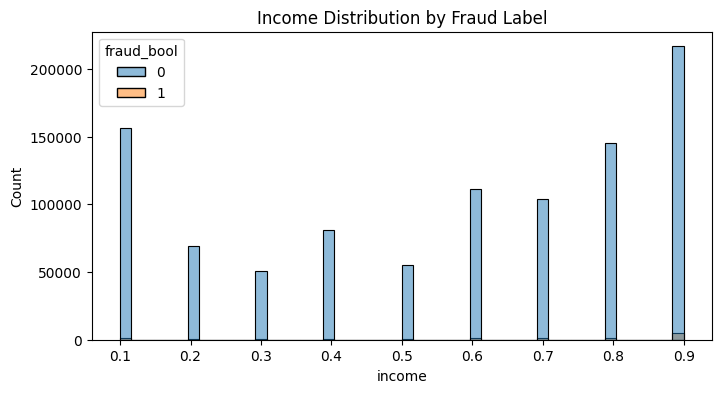

In [9]:
# Explore protected attributes

# Age group distribution
plt.figure(figsize=(8,4))
sns.countplot(x='customer_age', data=base_df, 
              hue='fraud_bool')
plt.title('Age Group Distribution by Fraud Label')
plt.savefig('age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Employment status distribution
plt.figure(figsize=(8,4))
sns.countplot(x='employment_status', data=base_df, 
              hue='fraud_bool')
plt.title('Employment Status Distribution by Fraud Label')
plt.savefig('employment_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Income percentage distribution
plt.figure(figsize=(8,4))
sns.histplot(data=base_df, x='income', 
             hue='fraud_bool', bins=50)
plt.title('Income Distribution by Fraud Label')
plt.savefig('income_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Check fraud rate by age group
print("Fraud rate by age group:")
print(base_df.groupby('customer_age')['fraud_bool'].mean().round(4) * 100)

# Check fraud rate by employment status
print("Fraud rate by employment status:")
print(base_df.groupby('employment_status')['fraud_bool'].mean().round(4) * 100)

# Check fraud rate by income level
print("Fraud rate by income level:")
print(base_df.groupby('income')['fraud_bool'].mean().round(4) * 100)

Fraud rate by age group:
customer_age
10    0.35
20    0.49
30    0.83
40    1.20
50    2.00
60    3.30
70    4.04
80    4.93
90    5.26
Name: fraud_bool, dtype: float64
Fraud rate by employment status:
employment_status
CA    1.22
CB    0.69
CC    2.47
CD    0.38
CE    0.23
CF    0.19
CG    1.55
Name: fraud_bool, dtype: float64
Fraud rate by income level:
income
0.1    0.58
0.2    0.63
0.3    0.66
0.4    0.73
0.5    0.79
0.6    0.88
0.7    0.88
0.8    1.09
0.9    2.16
Name: fraud_bool, dtype: float64


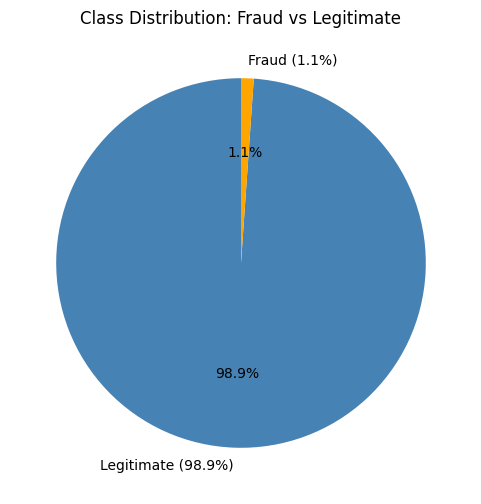

In [13]:
# Class imbalance pie chart
plt.figure(figsize=(6,6))
base_df['fraud_bool'].value_counts().plot(
    kind='pie',
    labels=['Legitimate (98.9%)', 'Fraud (1.1%)'],
    colors=['steelblue', 'orange'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Class Distribution: Fraud vs Legitimate')
plt.ylabel('')
plt.savefig('class_imbalance_pie.png', dpi=150, bbox_inches='tight')
plt.show()

**Version 1 Data Exploration**

Fraud rate by age group comparison:
              Base  Variant_I
customer_age                 
10            0.35       0.44
20            0.49       0.65
30            0.83       1.08
40            1.20       1.61
50            2.00       1.11
60            3.30       1.49
70            4.04       2.07
80            4.93       2.26
90            5.26       0.00


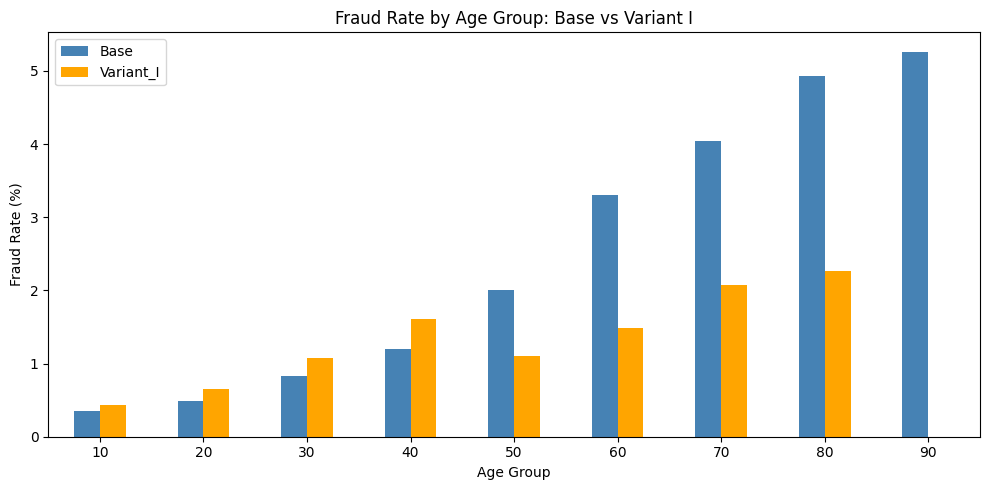

In [14]:
# Now load Variant I and compare fraud rates by age
variant1_df = pd.read_csv('Variant_1.csv')

base_age_fraud = base_df.groupby('customer_age')['fraud_bool'].mean() * 100
variant_age_fraud = variant1_df.groupby('customer_age')['fraud_bool'].mean() * 100

comparison = pd.DataFrame({
    'Base': base_age_fraud,
    'Variant_I': variant_age_fraud
})

print("Fraud rate by age group comparison:")
print(comparison.round(2))

comparison.plot(kind='bar', figsize=(10,5), color=['steelblue','orange'])
plt.title('Fraud Rate by Age Group: Base vs Variant I')
plt.ylabel('Fraud Rate (%)')
plt.xlabel('Age Group')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.savefig('age_bias_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Variant I Dataset Age Group Distribution**

In [15]:
total_var1 = len(variant1_df)

# Same grouping used for Base
var1_under50 = (variant1_df['customer_age'] < 50).sum()
var1_50plus = (variant1_df['customer_age'] >= 50).sum()

print("VARIANT I DATASET")
print("=" * 50)

print("Total applications:", total_var1)

print("\nAge < 50:")
print("Applications:", var1_under50)
print("Percentage:", round(var1_under50 / total_var1 * 100, 2), "%")

print("\nAge >= 50:")
print("Applications:", var1_50plus)
print("Percentage:", round(var1_50plus / total_var1 * 100, 2), "%")

VARIANT I DATASET
Total applications: 1000000

Age < 50:
Applications: 889301
Percentage: 88.93 %

Age >= 50:
Applications: 110699
Percentage: 11.07 %


**Fraud Prevalence by Age Group Across Base and Variant I**

In [16]:
# ============================================================
# FRAUD PREVALENCE BY AGE GROUP
# Base vs Variant I
# ============================================================

def fraud_prevalence_by_age(df, dataset_name):

    # Same grouping we used above
    younger = df[df['customer_age'] < 50]
    older = df[df['customer_age'] >= 50]

    # Fraud prevalence within each group
    younger_fraud_rate = younger['fraud_bool'].mean() * 100
    older_fraud_rate = older['fraud_bool'].mean() * 100

    print("\n" + "=" * 60)
    print(dataset_name)
    print("=" * 60)

    print("\nAGE < 50")
    print("Total applications :", len(younger))
    print("Fraud cases        :", int(younger['fraud_bool'].sum()))
    print("Fraud prevalence   :", round(younger_fraud_rate, 3), "%")

    print("\nAGE >= 50")
    print("Total applications :", len(older))
    print("Fraud cases        :", int(older['fraud_bool'].sum()))
    print("Fraud prevalence   :", round(older_fraud_rate, 3), "%")


# Run for both datasets
fraud_prevalence_by_age(base_df, "BASE DATASET")
fraud_prevalence_by_age(variant1_df, "VARIANT I DATASET")


BASE DATASET

AGE < 50
Total applications : 816987
Fraud cases        : 6744
Fraud prevalence   : 0.825 %

AGE >= 50
Total applications : 183013
Fraud cases        : 4285
Fraud prevalence   : 2.341 %

VARIANT I DATASET

AGE < 50
Total applications : 889301
Fraud cases        : 9683
Fraud prevalence   : 1.089 %

AGE >= 50
Total applications : 110699
Fraud cases        : 1346
Fraud prevalence   : 1.216 %


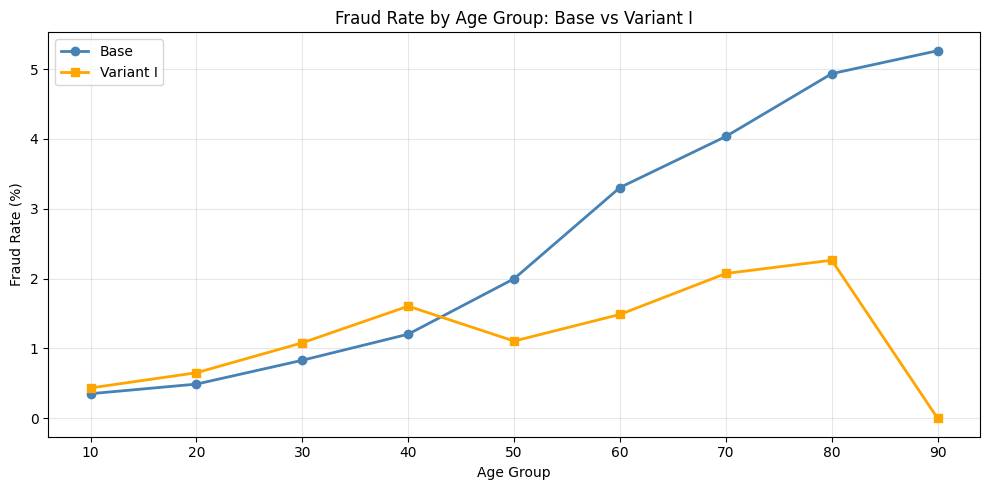

Base - fraud increases with age (older = more flagged)
Variant I - fraud pattern flattened/reversed for older groups

Key insight: Base dataset shows strong age gradient in fraud rate
This itself raises a FRIA fairness question


In [17]:
# Line chart to show the pattern more clearly
plt.figure(figsize=(10,5))
plt.plot(comparison.index, comparison['Base'], 
         marker='o', color='steelblue', 
         linewidth=2, label='Base')
plt.plot(comparison.index, comparison['Variant_I'], 
         marker='s', color='orange', 
         linewidth=2, label='Variant I')
plt.title('Fraud Rate by Age Group: Base vs Variant I')
plt.xlabel('Age Group')
plt.ylabel('Fraud Rate (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('age_fraud_line_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Also check what type of bias Variant I is documented to have
print("Base - fraud increases with age (older = more flagged)")
print("Variant I - fraud pattern flattened/reversed for older groups")
print("\nKey insight: Base dataset shows strong age gradient in fraud rate")
print("This itself raises a FRIA fairness question")

#  **DATA PRE-PROCESSING**

In [19]:
#Stratified Sampling

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns


# Stratified sample of 100,000 from Base
base_sample, _ = train_test_split(
    base_df,
    train_size=100000,
    stratify=base_df['fraud_bool'],
    random_state=42
)

# Stratified sample of 100,000 from Variant I
variant1_sample, _ = train_test_split(
    variant1_df,
    train_size=100000,
    stratify=variant1_df['fraud_bool'],
    random_state=42
)

print("Base sample shape:", base_sample.shape)
print("Variant I sample shape:", variant1_sample.shape)
print("\nBase sample fraud rate:", 
      round(base_sample['fraud_bool'].mean()*100, 2), "%")
print("Variant I sample fraud rate:", 
      round(variant1_sample['fraud_bool'].mean()*100, 2), "%")


# Drop the month column

base_sample = base_sample.drop(columns=['month'])
variant1_sample = variant1_sample.drop(columns=['month'])

print("Columns after dropping month:")
print(base_sample.columns.tolist())
print("Total columns:", len(base_sample.columns))


# Separate features and target, and note protected attributes

protected_attributes = ['customer_age', 'employment_status', 'income']

# Separate features (X) and target (y) for Base
X_base = base_sample.drop(columns=['fraud_bool'])
y_base = base_sample['fraud_bool']

# Separate features (X) and target (y) for Variant I
X_variant1 = variant1_sample.drop(columns=['fraud_bool'])
y_variant1 = variant1_sample['fraud_bool']

print("Feature columns:", X_base.columns.tolist())
print("\nProtected attributes:", protected_attributes)
print("\nTarget distribution in Base:")
print(y_base.value_counts())
print("\nTarget distribution in Variant I:")
print(y_variant1.value_counts())


#Encode categorical columns

# Identify categorical columns
categorical_cols = X_base.select_dtypes(include='object').columns.tolist()
print("Categorical columns to encode:", categorical_cols)

# Create label encoders and fit on Base, apply to both
# Important: fit only on Base to avoid data leakage from Variant I
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    # Fit on combined unique values from both datasets
    # to handle any unseen categories in Variant I
    combined_values = pd.concat([
        X_base[col], 
        X_variant1[col]
    ]).unique()
    le.fit(combined_values)
    
    # Apply to both datasets
    X_base[col] = le.transform(X_base[col])
    X_variant1[col] = le.transform(X_variant1[col])
    
    encoders[col] = le
    print(f"Encoded {col}: {list(le.classes_)}")

print("\nData types after encoding:")
print(X_base.dtypes)

# Verify no negative values cause issues

# Check for any -1 values which represent missing in BAF dataset
print("Columns with -1 values in Base:")
for col in X_base.columns:
    count = (X_base[col] == -1).sum()
    if count > 0:
        print(f"  {col}: {count} rows with -1")

print("\nColumns with -1 values in Variant I:")
for col in X_variant1.columns:
    count = (X_variant1[col] == -1).sum()
    if count > 0:
        print(f"  {col}: {count} rows with -1")




# Train-test split

# Split Base dataset
X_base_train, X_base_test, y_base_train, y_base_test = train_test_split(
    X_base, y_base,
    test_size=0.2,
    random_state=42,
    stratify=y_base
)

# Split Variant I dataset
X_var1_train, X_var1_test, y_var1_train, y_var1_test = train_test_split(
    X_variant1, y_variant1,
    test_size=0.2,
    random_state=42,
    stratify=y_variant1
)

print("Base training set:", X_base_train.shape)
print("Base test set:", X_base_test.shape)
print("Variant I training set:", X_var1_train.shape)
print("Variant I test set:", X_var1_test.shape)

print("\nBase train fraud rate:", 
      round(y_base_train.mean()*100, 2), "%")
print("Base test fraud rate:", 
      round(y_base_test.mean()*100, 2), "%")
print("Variant I train fraud rate:", 
      round(y_var1_train.mean()*100, 2), "%")
print("Variant I test fraud rate:", 
      round(y_var1_test.mean()*100, 2), "%")

        


Base sample shape: (100000, 32)
Variant I sample shape: (100000, 32)

Base sample fraud rate: 1.1 %
Variant I sample fraud rate: 1.1 %
Columns after dropping month:
['fraud_bool', 'income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'employment_status', 'credit_risk_score', 'email_is_free', 'housing_status', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source', 'session_length_in_minutes', 'device_os', 'keep_alive_session', 'device_distinct_emails_8w', 'device_fraud_count']
Total columns: 31
Feature columns: ['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount'

**Feature Standardisation and NumPy Conversion**

In [20]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# ---------------- Base ----------------
base_scaler = StandardScaler()

X_base_train = pd.DataFrame(
    base_scaler.fit_transform(X_base_train),
    columns=X_base_train.columns,
    index=X_base_train.index
)

X_base_test = pd.DataFrame(
    base_scaler.transform(X_base_test),
    columns=X_base_test.columns,
    index=X_base_test.index
)

# ---------------- Variant I ----------------
var1_scaler = StandardScaler()

X_var1_train = pd.DataFrame(
    var1_scaler.fit_transform(X_var1_train),
    columns=X_var1_train.columns,
    index=X_var1_train.index
)

X_var1_test = pd.DataFrame(
    var1_scaler.transform(X_var1_test),
    columns=X_var1_test.columns,
    index=X_var1_test.index
)

# Convert to NumPy
X_base_train_np = X_base_train.to_numpy(dtype=np.float32)
X_base_test_np = X_base_test.to_numpy(dtype=np.float32)

X_var1_train_np = X_var1_train.to_numpy(dtype=np.float32)
X_var1_test_np = X_var1_test.to_numpy(dtype=np.float32)

y_base_train_np = y_base_train.to_numpy(dtype=np.float32)
y_base_test_np = y_base_test.to_numpy(dtype=np.float32)

y_var1_train_np = y_var1_train.to_numpy(dtype=np.float32)
y_var1_test_np = y_var1_test.to_numpy(dtype=np.float32)

print("Scaling complete.")
print("Train shape:", X_base_train_np.shape)
print("Mean:", X_base_train_np.mean())
print("Std:", X_base_train_np.std())

Scaling complete.
Train shape: (80000, 30)
Mean: 1.1571248e-09
Std: 0.9831919


**Calculate class weights for handling imbalance**

In [21]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights for Base
base_class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=y_base_train
)
base_weight_dict = {0: base_class_weights[0], 
                    1: base_class_weights[1]}

# Calculate class weights for Variant I
var1_class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=y_var1_train
)
var1_weight_dict = {0: var1_class_weights[0], 
                    1: var1_class_weights[1]}

print("Base class weights:", base_weight_dict)
print("Variant I class weights:", var1_weight_dict)

Base class weights: {0: 0.5055739528299502, 1: 45.35147392290249}
Variant I class weights: {0: 0.5055739528299502, 1: 45.35147392290249}


**Convert to numpy arrays for TabNet**

In [22]:
# TabNet requires numpy arrays not pandas dataframes
X_base_train_np = X_base_train.values.astype(np.float32)
X_base_test_np = X_base_test.values.astype(np.float32)
y_base_train_np = y_base_train.values
y_base_test_np = y_base_test.values

X_var1_train_np = X_var1_train.values.astype(np.float32)
X_var1_test_np = X_var1_test.values.astype(np.float32)
y_var1_train_np = y_var1_train.values
y_var1_test_np = y_var1_test.values

# Save feature names for later use by FRIA agent
feature_names = X_base_train.columns.tolist()
print("Feature names saved:", feature_names)
print("\nTraining arrays ready for TabNet")
print("X_base_train shape:", X_base_train_np.shape)
print("X_var1_train shape:", X_var1_train_np.shape)

Feature names saved: ['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'employment_status', 'credit_risk_score', 'email_is_free', 'housing_status', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source', 'session_length_in_minutes', 'device_os', 'keep_alive_session', 'device_distinct_emails_8w', 'device_fraud_count']

Training arrays ready for TabNet
X_base_train shape: (80000, 30)
X_var1_train shape: (80000, 30)


In [23]:
print("=" * 50)
print("PRE-PROCESSING COMPLETE - SUMMARY")
print("=" * 50)
print(f"Base training samples:     {X_base_train_np.shape[0]}")
print(f"Base test samples:         {X_base_test_np.shape[0]}")
print(f"Variant I training samples:{X_var1_train_np.shape[0]}")
print(f"Variant I test samples:    {X_var1_test_np.shape[0]}")
print(f"Number of features:        {X_base_train_np.shape[1]}")
print(f"Protected attributes:      {protected_attributes}")
print(f"Feature names saved:       Yes")
print(f"Class weights calculated:  Yes")
print(f"Ready for TabNet training: Yes")
print("=" * 50)

PRE-PROCESSING COMPLETE - SUMMARY
Base training samples:     80000
Base test samples:         20000
Variant I training samples:80000
Variant I test samples:    20000
Number of features:        30
Protected attributes:      ['customer_age', 'employment_status', 'income']
Feature names saved:       Yes
Class weights calculated:  Yes
Ready for TabNet training: Yes


# **Model Training**

**Stratified Sampling and Train Test Split**

In [24]:
from sklearn.model_selection import train_test_split

# ============================================================
# RECREATE SAME 100,000 SAMPLES
# ============================================================

base_sample_raw, _ = train_test_split(
    base_df,
    train_size=100000,
    stratify=base_df["fraud_bool"],
    random_state=42
)

variant1_sample_raw, _ = train_test_split(
    variant1_df,
    train_size=100000,
    stratify=variant1_df["fraud_bool"],
    random_state=42
)

# Drop month exactly as before
base_sample_raw = base_sample_raw.drop(columns=["month"])
variant1_sample_raw = variant1_sample_raw.drop(columns=["month"])


# ============================================================
# SEPARATE X AND y
# ============================================================

X_base_raw = base_sample_raw.drop(columns=["fraud_bool"])
y_base_raw = base_sample_raw["fraud_bool"]

X_var1_raw = variant1_sample_raw.drop(columns=["fraud_bool"])
y_var1_raw = variant1_sample_raw["fraud_bool"]


# ============================================================
# RECREATE SAME 80/20 TEST SPLIT
# ============================================================

X_base_train_raw, X_base_test_raw, y_base_train_raw, y_base_test_raw = train_test_split(
    X_base_raw,
    y_base_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_base_raw
)

X_var1_train_raw, X_var1_test_raw, y_var1_train_raw, y_var1_test_raw = train_test_split(
    X_var1_raw,
    y_var1_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_var1_raw
)


print("Base test rows:", len(X_base_test_raw))
print("Variant I test rows:", len(X_var1_test_raw))

print("\nBase fraud cases:", int(y_base_test_raw.sum()))
print("Variant I fraud cases:", int(y_var1_test_raw.sum()))

print("\nFirst 20 REAL Base ages:")
print(X_base_test_raw["customer_age"].head(20).values)

print("\nFirst 20 REAL Variant I ages:")
print(X_var1_test_raw["customer_age"].head(20).values)

Base test rows: 20000
Variant I test rows: 20000

Base fraud cases: 221
Variant I fraud cases: 221

First 20 REAL Base ages:
[40 20 20 20 20 20 10 20 30 30 40 20 50 10 50 50 40 50 30 20]

First 20 REAL Variant I ages:
[30 40 50 30 30 20 30 30 30 40 40 30 40 20 30 30 30 40 20 20]


In [25]:
import psutil
mem = psutil.virtual_memory()
print(f"Total RAM: {mem.total / (1024**3):.1f} GB")
print(f"Available RAM: {mem.available / (1024**3):.1f} GB")
print(f"Used: {mem.percent}%")

Total RAM: 16.0 GB
Available RAM: 2.9 GB
Used: 81.8%


In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd
from sklearn.metrics import (classification_report, roc_auc_score, 
                             average_precision_score)
import matplotlib.pyplot as plt
import psutil

# Use MPS (Mac GPU) if available, otherwise CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)
print("Available RAM:", round(psutil.virtual_memory().available / (1024**3), 1), "GB")

Using device: mps
Available RAM: 3.0 GB


In [27]:
#Verify pre-processed data


print("Base training shape:", X_base_train_np.shape)
print("Base test shape:", X_base_test_np.shape)
print("Variant I training shape:", X_var1_train_np.shape)
print("Variant I test shape:", X_var1_test_np.shape)
print("Number of features:", len(feature_names))
print("Protected attributes:", protected_attributes)

Base training shape: (80000, 30)
Base test shape: (20000, 30)
Variant I training shape: (80000, 30)
Variant I test shape: (20000, 30)
Number of features: 30
Protected attributes: ['customer_age', 'employment_status', 'income']


In [28]:
# ============================================================
# Restore feature names
# ============================================================

feature_names = [
    'income',
    'name_email_similarity',
    'prev_address_months_count',
    'current_address_months_count',
    'customer_age',
    'days_since_request',
    'intended_balcon_amount',
    'payment_type',
    'zip_count_4w',
    'velocity_6h',
    'velocity_24h',
    'velocity_4w',
    'bank_branch_count_8w',
    'date_of_birth_distinct_emails_4w',
    'employment_status',
    'credit_risk_score',
    'email_is_free',
    'housing_status',
    'phone_home_valid',
    'phone_mobile_valid',
    'bank_months_count',
    'has_other_cards',
    'proposed_credit_limit',
    'foreign_request',
    'source',
    'session_length_in_minutes',
    'device_os',
    'keep_alive_session',
    'device_distinct_emails_8w',
    'device_fraud_count'
]

age_index = feature_names.index("customer_age")

print("Number of features:", len(feature_names))
print("customer_age column index:", age_index)

Number of features: 30
customer_age column index: 4


In [29]:
print("First 20 Base customer_age values:")
print(X_base_test_np[:20, 4])

print("\nBase age min:", X_base_test_np[:, 4].min())
print("Base age max:", X_base_test_np[:, 4].max())

print("\nFirst 20 Variant I customer_age values:")
print(X_var1_test_np[:20, 4])

print("\nVariant I age min:", X_var1_test_np[:, 4].min())
print("Variant I age max:", X_var1_test_np[:, 4].max())

First 20 Base customer_age values:
[ 0.5281329 -1.1331196 -1.1331196 -1.1331196 -1.1331196 -1.1331196
 -1.9637457 -1.1331196 -0.3024933 -0.3024933  0.5281329 -1.1331196
  1.3587592 -1.9637457  1.3587592  1.3587592  0.5281329  1.3587592
 -0.3024933 -1.1331196]

Base age min: -1.9637457
Base age max: 3.850638

First 20 Variant I customer_age values:
[-0.1782829  0.7395184  1.6573198 -0.1782829 -0.1782829 -1.0960842
 -0.1782829 -0.1782829 -0.1782829  0.7395184  0.7395184 -0.1782829
  0.7395184 -1.0960842 -0.1782829 -0.1782829 -0.1782829  0.7395184
 -1.0960842 -1.0960842]

Variant I age min: -2.0138855
Variant I age max: 4.4107237


In [30]:
print(base_class_weights)
print(base_weight_dict)

[ 0.50557395 45.35147392]
{0: 0.5055739528299502, 1: 45.35147392290249}


**ANN Model Architecture**

In [31]:
# Define ANN Model

class FraudANN(nn.Module):
    def __init__(self, input_dim):
        super(FraudANN, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16, 1)      # No Sigmoid here
        )

    def forward(self, x):
        return self.model(x)

In [32]:
# Create a reusable training function

def train_ann(X_train,
              y_train,
              class_weight_ratio,
              input_dim,
              epochs=20,
              batch_size=64,
              device=device):

    # Convert to tensors
    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)

    dataset = TensorDataset(X_tensor, y_tensor)
    dataloader = DataLoader(dataset,
                            batch_size=batch_size,
                            shuffle=True)

    # Build model
    model = FraudANN(input_dim).to(device)

    # Class weight
    pos_weight = torch.tensor(
        [float(class_weight_ratio)],
        dtype=torch.float32,
        device=device
    )

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Correct loss for imbalanced binary classification
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    history = {"loss": []}

    model.train()

    for epoch in range(epochs):

        running_loss = 0

        for batch_X, batch_y in dataloader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            logits = model(batch_X)

            loss = criterion(logits, batch_y)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        epoch_loss = running_loss / len(dataloader)
        history["loss"].append(epoch_loss)

        print(f"Epoch {epoch+1}/{epochs}  Loss: {epoch_loss:.4f}")

    return model, history

In [33]:
    # Train ANN on Base dataset
    
    ratio_base = float(base_class_weights[1])
    
    model_base, history_base = train_ann(
        X_base_train_np,
        y_base_train_np,
        class_weight_ratio=ratio_base,
        input_dim=len(feature_names),
        epochs=20,
        batch_size=64
    )

Epoch 1/20  Loss: 0.7666
Epoch 2/20  Loss: 0.6633
Epoch 3/20  Loss: 0.6496
Epoch 4/20  Loss: 0.6416
Epoch 5/20  Loss: 0.6255
Epoch 6/20  Loss: 0.6306
Epoch 7/20  Loss: 0.6227
Epoch 8/20  Loss: 0.6052
Epoch 9/20  Loss: 0.6095
Epoch 10/20  Loss: 0.6095
Epoch 11/20  Loss: 0.6069
Epoch 12/20  Loss: 0.5947
Epoch 13/20  Loss: 0.6036
Epoch 14/20  Loss: 0.5941
Epoch 15/20  Loss: 0.5889
Epoch 16/20  Loss: 0.5926
Epoch 17/20  Loss: 0.5905
Epoch 18/20  Loss: 0.5784
Epoch 19/20  Loss: 0.5797
Epoch 20/20  Loss: 0.5824


**Fairness Evaluation by Age Group**

In [34]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# ============================================================
# FAIRNESS METRICS BY AGE GROUP
# ============================================================

def calculate_age_fairness(X_test_raw, y_test_raw, y_pred, dataset_name):

    y_true = np.asarray(y_test_raw).flatten()
    y_pred = np.asarray(y_pred).flatten()

    # Get REAL age values
    ages = X_test_raw["customer_age"].to_numpy()

    groups = {
        "Age < 50": ages < 50,
        "Age >= 50": ages >= 50
    }

    results = []

    print("\n" + "=" * 65)
    print(dataset_name)
    print("=" * 65)

    for group_name, mask in groups.items():

        group_y_true = y_true[mask]
        group_y_pred = y_pred[mask]

        tn, fp, fn, tp = confusion_matrix(
            group_y_true,
            group_y_pred,
            labels=[0, 1]
        ).ravel()

        # True Positive Rate
        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0

        # False Positive Rate
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        # Percentage predicted as fraud
        predicted_positive_rate = group_y_pred.mean()

        print(f"\n{group_name}")
        print("-" * 40)

        print("Applications        :", len(group_y_true))
        print("Actual frauds       :", int(group_y_true.sum()))
        print("Predicted frauds    :", int(group_y_pred.sum()))

        print("\nConfusion matrix values")
        print("TP :", tp)
        print("FN :", fn)
        print("FP :", fp)
        print("TN :", tn)

        print("\nFairness metrics")
        print("TPR / Recall        :", round(tpr, 4))
        print("FPR                 :", round(fpr, 4))
        print("Predicted fraud rate:", round(predicted_positive_rate, 4))

        results.append({
            "Dataset": dataset_name,
            "Group": group_name,
            "Applications": len(group_y_true),
            "Actual_Frauds": int(group_y_true.sum()),
            "Predicted_Frauds": int(group_y_pred.sum()),
            "TPR": tpr,
            "FPR": fpr,
            "Predicted_Positive_Rate": predicted_positive_rate
        })

    return pd.DataFrame(results)

In [35]:
## Load saved ANN predictions for Base and Variant I



import numpy as np

# Load saved ANN predictions
y_base_pred = np.load(
    "ANN_results/metrics/Base_predictions.npy"
)

y_var1_pred = np.load(
    "ANN_results/metrics/Variant1_predictions.npy"
)

print("ANN predictions loaded successfully!")

print("\nBase predictions:", y_base_pred.shape)
print("Variant I predictions:", y_var1_pred.shape)

print("\nBase fraud predictions:", (y_base_pred == 1).sum())
print("Variant I fraud predictions:", (y_var1_pred == 1).sum())

ANN predictions loaded successfully!

Base predictions: (20000,)
Variant I predictions: (20000,)

Base fraud predictions: 1342
Variant I fraud predictions: 1356


In [36]:
#Calculate age group fairness metrics for Base ANN




base_ann_age_fairness = calculate_age_fairness(
    X_base_test_raw,
    y_base_test_raw,
    y_base_pred,
    "BASE ANN"
)

base_ann_age_fairness


BASE ANN

Age < 50
----------------------------------------
Applications        : 16386
Actual frauds       : 141
Predicted frauds    : 754

Confusion matrix values
TP : 68
FN : 73
FP : 686
TN : 15559

Fairness metrics
TPR / Recall        : 0.4823
FPR                 : 0.0422
Predicted fraud rate: 0.046

Age >= 50
----------------------------------------
Applications        : 3614
Actual frauds       : 80
Predicted frauds    : 588

Confusion matrix values
TP : 52
FN : 28
FP : 536
TN : 2998

Fairness metrics
TPR / Recall        : 0.65
FPR                 : 0.1517
Predicted fraud rate: 0.1627


,Dataset,Group,Applications,Actual_Frauds,Predicted_Frauds,TPR,FPR,Predicted_Positive_Rate
0,BASE ANN,Age < 50,16386,141,754,0.48227,0.042228,0.046015
1,BASE ANN,Age >= 50,3614,80,588,0.65000,0.151669,0.162701


In [47]:
#Calculate age group fairness metrics for Variant I ANN





variant1_ann_age_fairness = calculate_age_fairness(
    X_var1_test_raw,
    y_var1_test_raw,
    y_var1_pred,
    "VARIANT I ANN"
)

variant1_ann_age_fairness


VARIANT I ANN

Age < 50
----------------------------------------
Applications        : 17830
Actual frauds       : 198
Predicted frauds    : 1154

Confusion matrix values
TP : 90
FN : 108
FP : 1064
TN : 16568

Fairness metrics
TPR / Recall        : 0.4545
FPR                 : 0.0603
Predicted fraud rate: 0.0647

Age >= 50
----------------------------------------
Applications        : 2170
Actual frauds       : 23
Predicted frauds    : 202

Confusion matrix values
TP : 10
FN : 13
FP : 192
TN : 1955

Fairness metrics
TPR / Recall        : 0.4348
FPR                 : 0.0894
Predicted fraud rate: 0.0931


,Dataset,Group,Applications,Actual_Frauds,Predicted_Frauds,TPR,FPR,Predicted_Positive_Rate
0,VARIANT I ANN,Age < 50,17830,198,1154,0.454545,0.060345,0.064722
1,VARIANT I ANN,Age >= 50,2170,23,202,0.434783,0.089427,0.093088


In [37]:
#Evaluate Base model


def evaluate_model(model, X_test, y_test, threshold=0.5, device=device):

    model.eval()

    with torch.no_grad():

        X_tensor = torch.tensor(
            X_test,
            dtype=torch.float32
        ).to(device)

        logits = model(X_tensor)

        y_pred_prob = torch.sigmoid(logits).cpu().numpy().flatten()

    y_pred = (y_pred_prob >= threshold).astype(int)

    return y_pred_prob, y_pred

In [38]:
from sklearn.metrics import classification_report, confusion_matrix


y_base_pred_prob, y_base_pred = evaluate_model(
    model_base,
    X_base_test_np,
    y_base_test_np,
    threshold=0.5
)

print(classification_report(
    y_base_test_np,
    y_base_pred,
    target_names=["Legitimate","Fraud"],
    digits=4
))

print("ROC-AUC:",
      roc_auc_score(y_base_test_np,
                    y_base_pred_prob))

print("AUPRC:",
      average_precision_score(
          y_base_test_np,
          y_base_pred_prob
      ))

print("Fraud alerts:",
      (y_base_pred==1).sum())

print("Actual fraud:",
      int(y_base_test_np.sum()))



print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)

print(classification_report(
    y_base_test_np,
    y_base_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("="*60)
print("CONFUSION MATRIX")
print("="*60)

print(confusion_matrix(
    y_base_test_np,
    y_base_pred
))

              precision    recall  f1-score   support

  Legitimate     0.9957    0.9060    0.9487     19779
       Fraud     0.0714    0.6471    0.1287       221

    accuracy                         0.9032     20000
   macro avg     0.5335    0.7765    0.5387     20000
weighted avg     0.9855    0.9032    0.9397     20000

ROC-AUC: 0.875070090106537
AUPRC: 0.1415779718582775
Fraud alerts: 2002
Actual fraud: 221
CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate     0.9957    0.9060    0.9487     19779
       Fraud     0.0714    0.6471    0.1287       221

    accuracy                         0.9032     20000
   macro avg     0.5335    0.7765    0.5387     20000
weighted avg     0.9855    0.9032    0.9397     20000

CONFUSION MATRIX
[[17920  1859]
 [   78   143]]


# Explainability Analysis

## ANN Explainability Using SHAP

In [39]:

import shap
import torch
import numpy as np
import pandas as pd

def shap_by_age_group(
    model,
    X_train_np,
    X_test_np,
    X_test_raw,
    y_test_raw,
    y_pred,
    feature_names,
    dataset_name,
    max_samples=50
):
    
    print("\n" + "="*70)
    print(dataset_name)
    print("="*70)

    # Move model to CPU for SHAP
    model_cpu = model.to("cpu")
    model_cpu.eval()

    # --------------------------------------------------
    # SHAP background sample
    # --------------------------------------------------
    
    np.random.seed(42)

    background_idx = np.random.choice(
        len(X_train_np),
        size=min(100, len(X_train_np)),
        replace=False
    )

    X_background = torch.tensor(
        X_train_np[background_idx],
        dtype=torch.float32
    )

    explainer = shap.DeepExplainer(
        model_cpu,
        X_background
    )

    # --------------------------------------------------
    # Raw age and labels
    # --------------------------------------------------

    ages = X_test_raw["customer_age"].to_numpy()

    y_true = np.asarray(y_test_raw).flatten()
    y_pred = np.asarray(y_pred).flatten()

    # --------------------------------------------------
    # TRUE POSITIVE fraud cases
    # --------------------------------------------------

    true_positive_mask = (
        (y_true == 1) &
        (y_pred == 1)
    )

    # Age-group masks
    younger_mask = (
        true_positive_mask &
        (ages < 50)
    )

    older_mask = (
        true_positive_mask &
        (ages >= 50)
    )

    younger_idx = np.where(younger_mask)[0]
    older_idx = np.where(older_mask)[0]

    print("Correct frauds Age < 50 :", len(younger_idx))
    print("Correct frauds Age >=50 :", len(older_idx))

    # --------------------------------------------------
    # Random sample within each group
    # --------------------------------------------------

    np.random.seed(42)

    if len(younger_idx) > max_samples:
        younger_idx = np.random.choice(
            younger_idx,
            size=max_samples,
            replace=False
        )

    if len(older_idx) > max_samples:
        older_idx = np.random.choice(
            older_idx,
            size=max_samples,
            replace=False
        )

    # --------------------------------------------------
    # SHAP function
    # --------------------------------------------------

    def calculate_group_shap(indices, group_name):

        if len(indices) == 0:
            print(f"No samples found for {group_name}")
            return None, None

        X_group = torch.tensor(
            X_test_np[indices],
            dtype=torch.float32
        )

        shap_values = explainer.shap_values(
            X_group,
            check_additivity=False
        )

        if isinstance(shap_values, list):
            shap_values = shap_values[0]

        shap_values = np.array(shap_values)

        # Handle possible extra final dimension
        if shap_values.ndim == 3:
            shap_values = shap_values.squeeze(-1)

        print(
            f"{group_name} SHAP shape:",
            shap_values.shape
        )

        mean_abs_shap = np.abs(
            shap_values
        ).mean(axis=0)

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Mean_ABS_SHAP": mean_abs_shap
        })

        importance_df = importance_df.sort_values(
            "Mean_ABS_SHAP",
            ascending=False
        )

        return shap_values, importance_df

    # --------------------------------------------------
    # Calculate SHAP for each age group
    # --------------------------------------------------

    shap_younger, importance_younger = calculate_group_shap(
        younger_idx,
        "Age < 50"
    )

    shap_older, importance_older = calculate_group_shap(
        older_idx,
        "Age >= 50"
    )

    return {
        "younger_idx": younger_idx,
        "older_idx": older_idx,
        "shap_younger": shap_younger,
        "shap_older": shap_older,
        "importance_younger": importance_younger,
        "importance_older": importance_older
    }

In [43]:
# Define SHAP analysis by age group and prediction type
import shap
import torch
import numpy as np
import pandas as pd


def shap_by_age_and_error_type(
    model,
    X_train_np,
    X_test_np,
    X_test_raw,
    y_test_raw,
    y_pred,
    feature_names,
    dataset_name,
    max_samples=50
):

    print("\n" + "=" * 70)
    print(dataset_name)
    print("=" * 70)

    # SHAP is more stable on CPU
    model = model.to("cpu")
    model.eval()

    # -------------------------------
    # Background sample
    # -------------------------------

    np.random.seed(42)

    background_indices = np.random.choice(
        len(X_train_np),
        size=min(100, len(X_train_np)),
        replace=False
    )

    X_background = torch.tensor(
        X_train_np[background_indices],
        dtype=torch.float32
    )

    explainer = shap.DeepExplainer(
        model,
        X_background
    )

    # -------------------------------
    # Real ages + labels
    # -------------------------------

    ages = X_test_raw["customer_age"].to_numpy()

    y_true = np.asarray(y_test_raw).flatten()
    y_pred = np.asarray(y_pred).flatten()

    # -------------------------------
    # Helper to calculate SHAP
    # -------------------------------

    def calculate_shap(indices, group_label):

        print("\n" + "-" * 55)
        print(group_label)
        print("Cases available:", len(indices))

        if len(indices) == 0:
            print("No cases available.")
            return None, None

        # Limit to max_samples
        if len(indices) > max_samples:

            rng = np.random.default_rng(42)

            indices = rng.choice(
                indices,
                size=max_samples,
                replace=False
            )

        X_group = torch.tensor(
            X_test_np[indices],
            dtype=torch.float32
        )

        shap_values = explainer.shap_values(
            X_group,
            check_additivity=False
        )

        if isinstance(shap_values, list):
            shap_values = shap_values[0]

        shap_values = np.asarray(shap_values)

        # Some SHAP versions return (samples, features, 1)
        if shap_values.ndim == 3:
            shap_values = shap_values.squeeze(-1)

        mean_abs = np.abs(
            shap_values
        ).mean(axis=0)

        importance = pd.DataFrame({
            "Feature": feature_names,
            "Mean_ABS_SHAP": mean_abs
        }).sort_values(
            "Mean_ABS_SHAP",
            ascending=False
        )

        print("Samples analysed:", len(indices))
        print("SHAP shape:", shap_values.shape)

        return shap_values, importance

    # ========================================================
    # TRUE POSITIVES
    # ========================================================

    tp_mask = (
        (y_true == 1) &
        (y_pred == 1)
    )

    tp_under50 = np.where(
        tp_mask &
        (ages < 50)
    )[0]

    tp_50plus = np.where(
        tp_mask &
        (ages >= 50)
    )[0]

    # ========================================================
    # FALSE POSITIVES
    # ========================================================

    fp_mask = (
        (y_true == 0) &
        (y_pred == 1)
    )

    fp_under50 = np.where(
        fp_mask &
        (ages < 50)
    )[0]

    fp_50plus = np.where(
        fp_mask &
        (ages >= 50)
    )[0]

    print("\nCases found:")
    print("TP <50  :", len(tp_under50))
    print("TP >=50 :", len(tp_50plus))
    print("FP <50  :", len(fp_under50))
    print("FP >=50 :", len(fp_50plus))

    # -------------------------------
    # Calculate SHAP
    # -------------------------------

    tp_under50_shap, tp_under50_imp = calculate_shap(
        tp_under50,
        "TRUE POSITIVES - Age <50"
    )

    tp_50plus_shap, tp_50plus_imp = calculate_shap(
        tp_50plus,
        "TRUE POSITIVES - Age >=50"
    )

    fp_under50_shap, fp_under50_imp = calculate_shap(
        fp_under50,
        "FALSE POSITIVES - Age <50"
    )

    fp_50plus_shap, fp_50plus_imp = calculate_shap(
        fp_50plus,
        "FALSE POSITIVES - Age >=50"
    )

    return {

        "TP_under50": tp_under50_imp,
        "TP_50plus": tp_50plus_imp,

        "FP_under50": fp_under50_imp,
        "FP_50plus": fp_50plus_imp,

        "TP_under50_values": tp_under50_shap,
        "TP_50plus_values": tp_50plus_shap,

        "FP_under50_values": fp_under50_shap,
        "FP_50plus_values": fp_50plus_shap
    }

In [44]:
#Generate SHAP explanations for Base ANN
base_age_shap = shap_by_age_and_error_type(
    model=model_base,
    X_train_np=X_base_train_np,
    X_test_np=X_base_test_np,
    X_test_raw=X_base_test_raw,
    y_test_raw=y_base_test_raw,
    y_pred=y_base_pred,
    feature_names=feature_names,
    dataset_name="BASE ANN",
    max_samples=50
)


BASE ANN

Cases found:
TP <50  : 78
TP >=50 : 65
FP <50  : 1124
FP >=50 : 735

-------------------------------------------------------
TRUE POSITIVES - Age <50
Cases available: 78
Samples analysed: 50
SHAP shape: (50, 30)

-------------------------------------------------------
TRUE POSITIVES - Age >=50
Cases available: 65
Samples analysed: 50
SHAP shape: (50, 30)

-------------------------------------------------------
FALSE POSITIVES - Age <50
Cases available: 1124
Samples analysed: 50
SHAP shape: (50, 30)

-------------------------------------------------------
FALSE POSITIVES - Age >=50
Cases available: 735
Samples analysed: 50
SHAP shape: (50, 30)


In [45]:

print("\nBASE ANN - TRUE POSITIVES - AGE <50")
display(base_age_shap["TP_under50"].head(15))

print("\nBASE ANN - TRUE POSITIVES - AGE >=50")
display(base_age_shap["TP_50plus"].head(15))

print("\nBASE ANN - FALSE POSITIVES - AGE <50")
display(base_age_shap["FP_under50"].head(15))

print("\nBASE ANN - FALSE POSITIVES - AGE >=50")
display(base_age_shap["FP_50plus"].head(15))


BASE ANN - TRUE POSITIVES - AGE <50


,Feature,Mean_ABS_SHAP
17,housing_status,0.113758
27,keep_alive_session,0.072203
0,income,0.066376
18,phone_home_valid,0.062862
26,device_os,0.058889
21,has_other_cards,0.057736
16,email_is_free,0.051606
15,credit_risk_score,0.050153
1,name_email_similarity,0.049608
22,proposed_credit_limit,0.039325



BASE ANN - TRUE POSITIVES - AGE >=50


,Feature,Mean_ABS_SHAP
17,housing_status,0.111902
27,keep_alive_session,0.075557
18,phone_home_valid,0.065454
26,device_os,0.064919
4,customer_age,0.063056
0,income,0.057189
21,has_other_cards,0.051497
16,email_is_free,0.048013
13,date_of_birth_distinct_emails_4w,0.047738
1,name_email_similarity,0.046808



BASE ANN - FALSE POSITIVES - AGE <50


,Feature,Mean_ABS_SHAP
17,housing_status,0.098537
27,keep_alive_session,0.071092
18,phone_home_valid,0.067908
0,income,0.060979
21,has_other_cards,0.058111
26,device_os,0.052183
16,email_is_free,0.050227
1,name_email_similarity,0.045426
8,zip_count_4w,0.039672
15,credit_risk_score,0.037342



BASE ANN - FALSE POSITIVES - AGE >=50


,Feature,Mean_ABS_SHAP
17,housing_status,0.098058
27,keep_alive_session,0.074714
4,customer_age,0.065866
18,phone_home_valid,0.064512
21,has_other_cards,0.057509
26,device_os,0.056162
0,income,0.052990
16,email_is_free,0.048024
13,date_of_birth_distinct_emails_4w,0.044909
22,proposed_credit_limit,0.043873


In [28]:
#Train ANN on Variant I


ratio_var1 = float(var1_class_weights[1])

print("="*60)
print("Training ANN on Variant I Dataset")
print("="*60)

model_var1, history_var1 = train_ann(
    X_var1_train_np,
    y_var1_train_np,
    class_weight_ratio=ratio_var1,
    input_dim=len(feature_names),
    epochs=20,
    batch_size=64
)

print("\nTraining completed successfully!")

Training ANN on Variant I Dataset
Epoch 1/20  Loss: 0.7977
Epoch 2/20  Loss: 0.7147
Epoch 3/20  Loss: 0.7037
Epoch 4/20  Loss: 0.6885
Epoch 5/20  Loss: 0.6818
Epoch 6/20  Loss: 0.6844
Epoch 7/20  Loss: 0.6752
Epoch 8/20  Loss: 0.6630
Epoch 9/20  Loss: 0.6683
Epoch 10/20  Loss: 0.6569
Epoch 11/20  Loss: 0.6537
Epoch 12/20  Loss: 0.6466
Epoch 13/20  Loss: 0.6550
Epoch 14/20  Loss: 0.6488
Epoch 15/20  Loss: 0.6426
Epoch 16/20  Loss: 0.6387
Epoch 17/20  Loss: 0.6323
Epoch 18/20  Loss: 0.6394
Epoch 19/20  Loss: 0.6296
Epoch 20/20  Loss: 0.6318

Training completed successfully!


In [3]:
#Evaluate Variant I model


# ==========================================
# Evaluate Variant I Model
# ==========================================

y_var1_pred_prob, y_var1_pred = evaluate_model(
    model_var1,
    X_var1_test_np,
    y_var1_test_np,
    threshold=0.5
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("="*60)
print("VARIANT I MODEL PERFORMANCE")
print("="*60)

print(classification_report(
    y_var1_test_np,
    y_var1_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("="*60)
print("Confusion Matrix")
print("="*60)

print(confusion_matrix(
    y_var1_test_np,
    y_var1_pred
))

print("\nOverall Metrics")
print("-"*40)

print(f"Accuracy : {accuracy_score(y_var1_test_np, y_var1_pred):.4f}")
print(f"Precision: {precision_score(y_var1_test_np, y_var1_pred):.4f}")
print(f"Recall   : {recall_score(y_var1_test_np, y_var1_pred):.4f}")
print(f"F1-score : {f1_score(y_var1_test_np, y_var1_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_var1_test_np, y_var1_pred_prob):.4f}")
print(f"AUPRC    : {average_precision_score(y_var1_test_np, y_var1_pred_prob):.4f}")

print("\nFraud alerts generated :", (y_var1_pred == 1).sum())
print("Actual fraud cases     :", int(y_var1_test_np.sum()))

NameError: name 'evaluate_model' is not defined

In [ ]:
#compare both models


roc_base = roc_auc_score(y_base_test_np, y_base_pred_prob)
auprc_base = average_precision_score(y_base_test_np, y_base_pred_prob)
roc_var1 = roc_auc_score(y_var1_test_np, y_var1_pred_prob)
auprc_var1 = average_precision_score(y_var1_test_np, y_var1_pred_prob)

print("="*55)
print("MODEL COMPARISON: BASE vs VARIANT I")
print("="*55)
print(f"{'Metric':<25} {'Base':>10} {'Variant I':>12}")
print("-"*55)
print(f"{'ROC-AUC':<25} {roc_base:>10.4f} {roc_var1:>12.4f}")
print(f"{'AUPRC':<25} {auprc_base:>10.4f} {auprc_var1:>12.4f}")
print("="*55)

NameError: name 'history_variant1' is not defined

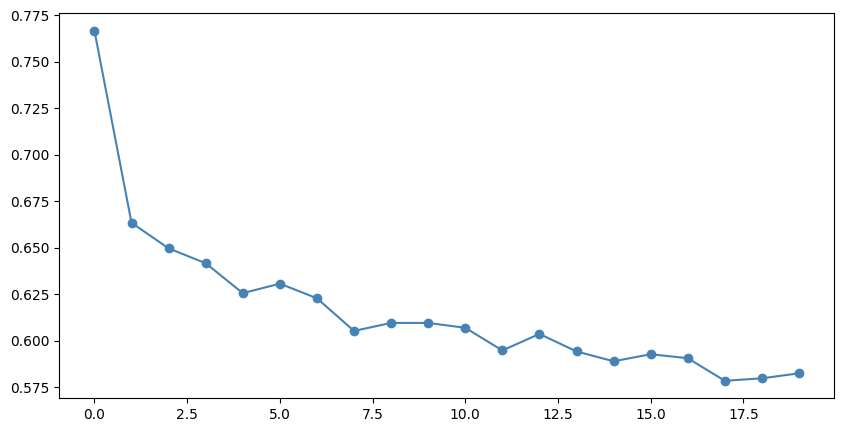

In [48]:
#Plot training loss for both models


plt.figure(figsize=(10, 5))
plt.plot(history_base['loss'], label='Base Dataset', 
         color='steelblue', marker='o')
plt.plot(history_variant1['loss'], label='Variant I Dataset', 
         color='orange', marker='s')
plt.title('ANN Training Loss: Base vs Variant I')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ann_training_loss_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# SHAP on Variant1

In [50]:
#extraaa




# ============================================================
# VARIANT I ANN - SHAP BY AGE GROUP AND ERROR TYPE
# ============================================================

variant1_age_shap = shap_by_age_and_error_type(
    model=model_var1,
    X_train_np=X_var1_train_np,
    X_test_np=X_var1_test_np,
    X_test_raw=X_var1_test_raw,
    y_test_raw=y_var1_test_raw,
    y_pred=y_var1_pred,
    feature_names=feature_names,
    dataset_name="VARIANT I ANN",
    max_samples=50
)


VARIANT I ANN

Cases found:
TP <50  : 90
TP >=50 : 10
FP <50  : 1064
FP >=50 : 192

-------------------------------------------------------
TRUE POSITIVES - Age <50
Cases available: 90
Samples analysed: 50
SHAP shape: (50, 30)

-------------------------------------------------------
TRUE POSITIVES - Age >=50
Cases available: 10
Samples analysed: 10
SHAP shape: (10, 30)

-------------------------------------------------------
FALSE POSITIVES - Age <50
Cases available: 1064
Samples analysed: 50
SHAP shape: (50, 30)

-------------------------------------------------------
FALSE POSITIVES - Age >=50
Cases available: 192
Samples analysed: 50
SHAP shape: (50, 30)


In [51]:
#extraaa



print("\nVARIANT I ANN - TRUE POSITIVES - AGE <50")
display(variant1_age_shap["TP_under50"].head(15))

print("\nVARIANT I ANN - TRUE POSITIVES - AGE >=50")
display(variant1_age_shap["TP_50plus"].head(15))

print("\nVARIANT I ANN - FALSE POSITIVES - AGE <50")
display(variant1_age_shap["FP_under50"].head(15))

print("\nVARIANT I ANN - FALSE POSITIVES - AGE >=50")
display(variant1_age_shap["FP_50plus"].head(15))


VARIANT I ANN - TRUE POSITIVES - AGE <50


,Feature,Mean_ABS_SHAP
17,housing_status,0.108282
27,keep_alive_session,0.068877
18,phone_home_valid,0.055890
26,device_os,0.054606
3,current_address_months_count,0.054244
16,email_is_free,0.049073
0,income,0.047017
1,name_email_similarity,0.039231
15,credit_risk_score,0.034140
7,payment_type,0.028430



VARIANT I ANN - TRUE POSITIVES - AGE >=50


,Feature,Mean_ABS_SHAP
17,housing_status,0.075998
28,device_distinct_emails_8w,0.065693
27,keep_alive_session,0.060481
26,device_os,0.057922
3,current_address_months_count,0.055974
18,phone_home_valid,0.053709
16,email_is_free,0.039998
1,name_email_similarity,0.028492
0,income,0.027321
15,credit_risk_score,0.026044



VARIANT I ANN - FALSE POSITIVES - AGE <50


,Feature,Mean_ABS_SHAP
17,housing_status,0.087969
18,phone_home_valid,0.063080
27,keep_alive_session,0.062372
26,device_os,0.054817
3,current_address_months_count,0.051418
16,email_is_free,0.046833
0,income,0.045748
1,name_email_similarity,0.033259
14,employment_status,0.029810
7,payment_type,0.026961



VARIANT I ANN - FALSE POSITIVES - AGE >=50


,Feature,Mean_ABS_SHAP
17,housing_status,0.099423
18,phone_home_valid,0.061777
3,current_address_months_count,0.061177
27,keep_alive_session,0.055887
26,device_os,0.055620
0,income,0.043272
16,email_is_free,0.042027
15,credit_risk_score,0.034818
1,name_email_similarity,0.029154
21,has_other_cards,0.027623


# Saving ANN results

In [55]:
import torch

torch.save(model_base.state_dict(),
           "ANN_results/models/ann_base_model.pth")

torch.save(model_var1.state_dict(),
           "ANN_results/models/ann_variant1_model.pth")

print("ANN models saved successfully!")

ANN models saved successfully!


In [56]:
import os
import torch

os.makedirs("ANN_results", exist_ok=True)
os.makedirs("ANN_results/models", exist_ok=True)
os.makedirs("ANN_results/shap", exist_ok=True)
os.makedirs("ANN_results/metrics", exist_ok=True)

print("ANN results folders created")

# Save Base ANN model
torch.save(
    model_base.state_dict(),
    "ANN_results/models/ANN_Base_model.pth"
)


# Save Variant I ANN model
torch.save(
    model_var1.state_dict(),
    "ANN_results/models/ANN_Variant1_model.pth"
)


print("ANN models saved successfully")



ANN results folders created
ANN models saved successfully


In [185]:
    import numpy as np
    
    
    # Base predictions
    np.save(
        "ANN_results/metrics/Base_pred_prob.npy",
        y_base_pred_prob
    )
    
    np.save(
        "ANN_results/metrics/Base_predictions.npy",
        y_base_pred
    )
    
    
    # Variant I predictions
    np.save(
        "ANN_results/metrics/Variant1_pred_prob.npy",
        y_var1_pred_prob
    )
    
    np.save(
        "ANN_results/metrics/Variant1_predictions.npy",
        y_var1_pred
    )
    
    
    print("Predictions saved")

Predictions saved


In [60]:
from sklearn.metrics import classification_report


base_report = classification_report(
    y_base_test_np,
    y_base_pred,
    target_names=[
        "Legitimate",
        "Fraud"
    ],
    output_dict=True
)


variant1_report = classification_report(
    y_var1_test_np,
    y_var1_pred,
    target_names=[
        "Legitimate",
        "Fraud"
    ],
    output_dict=True
)


pd.DataFrame(base_report).transpose().to_csv(
    "ANN_results/metrics/Base_classification_report.csv"
)


pd.DataFrame(variant1_report).transpose().to_csv(
    "ANN_results/metrics/Variant1_classification_report.csv"
)


print("Classification reports saved")

Classification reports saved


In [61]:
from sklearn.metrics import confusion_matrix


base_cm = confusion_matrix(
    y_base_test_np,
    y_base_pred
)


variant1_cm = confusion_matrix(
    y_var1_test_np,
    y_var1_pred
)


np.save(
    "ANN_results/metrics/Base_confusion_matrix.npy",
    base_cm
)


np.save(
    "ANN_results/metrics/Variant1_confusion_matrix.npy",
    variant1_cm
)


print("Confusion matrices saved")

Confusion matrices saved


# TabNet

In [192]:
!pip install pytorch-tabnet

  Using cached pytorch_tabnet-4.1.0-py3-none-any.whl.metadata (15 kB)
Using cached pytorch_tabnet-4.1.0-py3-none-any.whl (44 kB)


In [42]:
from pytorch_tabnet.tab_model import TabNetClassifier

print("TabNet installed successfully!")

TabNet installed successfully!


In [43]:
import importlib.metadata

print(importlib.metadata.version("pytorch-tabnet"))


4.1.0


In [44]:
# ============================================================
# TABNET IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pytorch_tabnet.tab_model import TabNetClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("TabNet imported successfully!")

TabNet imported successfully!


In [45]:
# ============================================================
# PREPARE DATA
# ============================================================

X_base_train_tabnet = X_base_train.values.astype(np.float32)
X_base_test_tabnet  = X_base_test.values.astype(np.float32)

X_var1_train_tabnet = X_var1_train.values.astype(np.float32)
X_var1_test_tabnet  = X_var1_test.values.astype(np.float32)

y_base_train_tabnet = y_base_train.values
y_base_test_tabnet  = y_base_test.values

y_var1_train_tabnet = y_var1_train.values
y_var1_test_tabnet  = y_var1_test.values

print("Base train:", X_base_train_tabnet.shape)
print("Base test :", X_base_test_tabnet.shape)

print("Variant train:", X_var1_train_tabnet.shape)
print("Variant test :", X_var1_test_tabnet.shape)

Base train: (80000, 30)
Base test : (20000, 30)
Variant train: (80000, 30)
Variant test : (20000, 30)


In [51]:
# ============================================================
# TRAIN BASE TABNET
# ============================================================

tabnet_base = TabNetClassifier(

    n_d=32,
    n_a=32,
    n_steps=5,
    gamma=1.5,

    optimizer_params=dict(lr=2e-2),

    scheduler_params={
        "step_size":20,
        "gamma":0.9
    },

    scheduler_fn=torch.optim.lr_scheduler.StepLR,

    mask_type='entmax',

    verbose=10

)

print("="*60)
print("Training Base TabNet")
print("="*60)

tabnet_base.fit(

    X_train=X_base_train_tabnet,
    y_train=y_base_train_tabnet,

    eval_set=[
        (X_base_test_tabnet,
         y_base_test_tabnet)
    ],

    eval_name=["Validation"],

    eval_metric=["auc"],

    max_epochs=100,

    patience=20,

    batch_size=1024,

    virtual_batch_size=128,

    num_workers=0,

    drop_last=False,

    weights=1

)

print("Base training completed!")

Device used : cpu


Training Base TabNet
epoch 0  | loss: 0.57388 | Validation_auc: 0.82006 |  0:00:05s
epoch 10 | loss: 0.1973  | Validation_auc: 0.82525 |  0:01:10s
epoch 20 | loss: 0.08002 | Validation_auc: 0.74594 |  0:02:15s

Early stopping occurred at epoch 21 with best_epoch = 1 and best_Validation_auc = 0.84129


Best weights from best epoch are automatically used!


Base training completed!


In [52]:
# ============================================================
# EVALUATE BASE MODEL
# ============================================================

threshold = 0.5

y_prob_base = tabnet_base.predict_proba(
    X_base_test_tabnet
)[:,1]

y_pred_base = (
    y_prob_base >= threshold
).astype(int)

print("="*60)
print("BASE MODEL PERFORMANCE")
print("="*60)

print(classification_report(
    y_base_test_tabnet,
    y_pred_base,
    target_names=[
        "Legitimate",
        "Fraud"
    ],
    digits=4
))

cm = confusion_matrix(
    y_base_test_tabnet,
    y_pred_base
)

print("\nConfusion Matrix")
print(cm)

print("\nAccuracy :", accuracy_score(
    y_base_test_tabnet,
    y_pred_base))

print("Precision:",
      precision_score(
          y_base_test_tabnet,
          y_pred_base))

print("Recall   :",
      recall_score(
          y_base_test_tabnet,
          y_pred_base))

print("F1 Score :",
      f1_score(
          y_base_test_tabnet,
          y_pred_base))

print("ROC AUC  :",
      roc_auc_score(
          y_base_test_tabnet,
          y_prob_base))

print("AUPRC    :",
      average_precision_score(
          y_base_test_tabnet,
          y_prob_base))

print("\nFraud Alerts:",
      (y_pred_base==1).sum())

print("Actual Fraud:",
      y_base_test_tabnet.sum())

BASE MODEL PERFORMANCE
              precision    recall  f1-score   support

  Legitimate     0.9961    0.7969    0.8855     19779
       Fraud     0.0383    0.7240    0.0728       221

    accuracy                         0.7961     20000
   macro avg     0.5172    0.7604    0.4791     20000
weighted avg     0.9856    0.7961    0.8765     20000


Confusion Matrix
[[15762  4017]
 [   61   160]]

Accuracy : 0.7961
Precision: 0.03830500359109409
Recall   : 0.7239819004524887
F1 Score : 0.07276034561164166
ROC AUC  : 0.841289689988399
AUPRC    : 0.07932084789832357

Fraud Alerts: 4177
Actual Fraud: 221


In [53]:
# ============================================================
# THRESHOLD TUNING
# ============================================================

thresholds=np.arange(
    0.1,
    1.0,
    0.1
)

results=[]

for t in thresholds:

    pred=(y_prob_base>=t).astype(int)

    precision=precision_score(
        y_base_test_tabnet,
        pred,
        zero_division=0
    )

    recall=recall_score(
        y_base_test_tabnet,
        pred
    )

    f1=f1_score(
        y_base_test_tabnet,
        pred
    )

    results.append([
        t,
        precision,
        recall,
        f1
    ])

results=pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Precision",
        "Recall",
        "F1"
    ]
)

print(results)

   Threshold  Precision    Recall        F1
0        0.1   0.015527  0.954751  0.030558
1        0.2   0.020030  0.918552  0.039204
2        0.3   0.025867  0.891403  0.050274
3        0.4   0.031575  0.809955  0.060781
4        0.5   0.038305  0.723982  0.072760
5        0.6   0.047306  0.651584  0.088208
6        0.7   0.060143  0.570136  0.108808
7        0.8   0.070488  0.411765  0.120370
8        0.9   0.109665  0.266968  0.155468


,Feature,Importance
17,housing_status,0.101486
27,keep_alive_session,0.099210
4,customer_age,0.070914
7,payment_type,0.069944
18,phone_home_valid,0.065335
0,income,0.059257
21,has_other_cards,0.054636
6,intended_balcon_amount,0.049660
10,velocity_24h,0.045607
26,device_os,0.040423


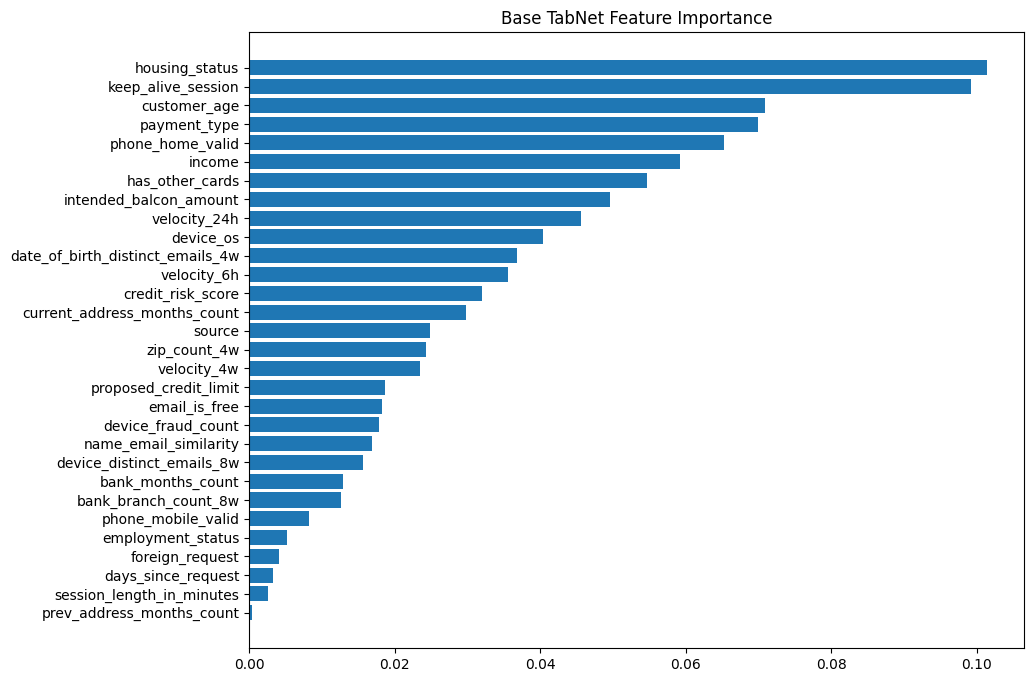

In [54]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importance=pd.DataFrame({

    "Feature":feature_names,

    "Importance":
    tabnet_base.feature_importances_

})

importance=importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(10,8))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title(
    "Base TabNet Feature Importance"
)

plt.show()

**TabNet Model Training**

In [55]:
# ============================================================
# TRAIN VARIANT I TABNET
# ============================================================

import torch

tabnet_var1 = TabNetClassifier(

    n_d=32,
    n_a=32,
    n_steps=5,
    gamma=1.5,

    optimizer_fn=torch.optim.Adam,

    optimizer_params=dict(
        lr=2e-2
    ),

    scheduler_fn=torch.optim.lr_scheduler.StepLR,

    scheduler_params={
        "step_size":20,
        "gamma":0.9
    },

    mask_type="entmax",

    verbose=10
)

print("="*60)
print("Training Variant I TabNet")
print("="*60)

tabnet_var1.fit(

    X_train=X_var1_train_tabnet,
    y_train=y_var1_train_tabnet,

    eval_set=[
        (X_var1_test_tabnet,
         y_var1_test_tabnet)
    ],

    eval_name=["Validation"],

    eval_metric=["auc"],

    max_epochs=100,

    patience=20,

    batch_size=1024,

    virtual_batch_size=128,

    num_workers=0,

    drop_last=False,

    weights=1

)

print("\nTraining completed successfully!")

Device used : cpu


Training Variant I TabNet
epoch 0  | loss: 0.60845 | Validation_auc: 0.8233  |  0:00:05s
epoch 10 | loss: 0.23312 | Validation_auc: 0.77087 |  0:00:57s
epoch 20 | loss: 0.08632 | Validation_auc: 0.77582 |  0:01:49s

Early stopping occurred at epoch 22 with best_epoch = 2 and best_Validation_auc = 0.82582


Best weights from best epoch are automatically used!



Training completed successfully!


**TabNet Model Evaluation**

In [56]:
# ============================================================
# EVALUATE VARIANT I MODEL
# ============================================================

threshold = 0.5

# Predict probabilities
y_var1_prob = tabnet_var1.predict_proba(
    X_var1_test_tabnet
)[:,1]

# Convert probabilities to predictions
y_var1_pred = (
    y_var1_prob >= threshold
).astype(int)

print("="*60)
print("VARIANT I MODEL PERFORMANCE")
print("="*60)

print(classification_report(
    y_var1_test_tabnet,
    y_var1_pred,
    target_names=[
        "Legitimate",
        "Fraud"
    ],
    digits=4
))

# ------------------------------------------------

cm = confusion_matrix(
    y_var1_test_tabnet,
    y_var1_pred
)

print("\n"+"="*60)
print("CONFUSION MATRIX")
print("="*60)

print(cm)

# ------------------------------------------------

accuracy = accuracy_score(
    y_var1_test_tabnet,
    y_var1_pred
)

precision = precision_score(
    y_var1_test_tabnet,
    y_var1_pred,
    zero_division=0
)

recall = recall_score(
    y_var1_test_tabnet,
    y_var1_pred
)

f1 = f1_score(
    y_var1_test_tabnet,
    y_var1_pred
)

roc = roc_auc_score(
    y_var1_test_tabnet,
    y_var1_prob
)

auprc = average_precision_score(
    y_var1_test_tabnet,
    y_var1_prob
)

print("\nOverall Metrics")
print("-"*40)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1-score :", round(f1,4))
print("ROC-AUC  :", round(roc,4))
print("AUPRC    :", round(auprc,4))

print("\nFraud alerts generated :", (y_var1_pred==1).sum())
print("Actual fraud cases     :", int(y_var1_test_tabnet.sum()))

VARIANT I MODEL PERFORMANCE
              precision    recall  f1-score   support

  Legitimate     0.9964    0.7528    0.8576     19779
       Fraud     0.0330    0.7557    0.0633       221

    accuracy                         0.7529     20000
   macro avg     0.5147    0.7542    0.4605     20000
weighted avg     0.9857    0.7529    0.8489     20000


CONFUSION MATRIX
[[14890  4889]
 [   54   167]]

Overall Metrics
----------------------------------------
Accuracy : 0.7529
Precision: 0.033
Recall   : 0.7557
F1-score : 0.0633
ROC-AUC  : 0.8258
AUPRC    : 0.0817

Fraud alerts generated : 5056
Actual fraud cases     : 221


VARIANT I FEATURE IMPORTANCE


,Feature,Importance
17,housing_status,0.150576
18,phone_home_valid,0.108982
0,income,0.061382
1,name_email_similarity,0.060666
27,keep_alive_session,0.056951
2,prev_address_months_count,0.053133
11,velocity_4w,0.048036
4,customer_age,0.047604
26,device_os,0.042657
19,phone_mobile_valid,0.036395


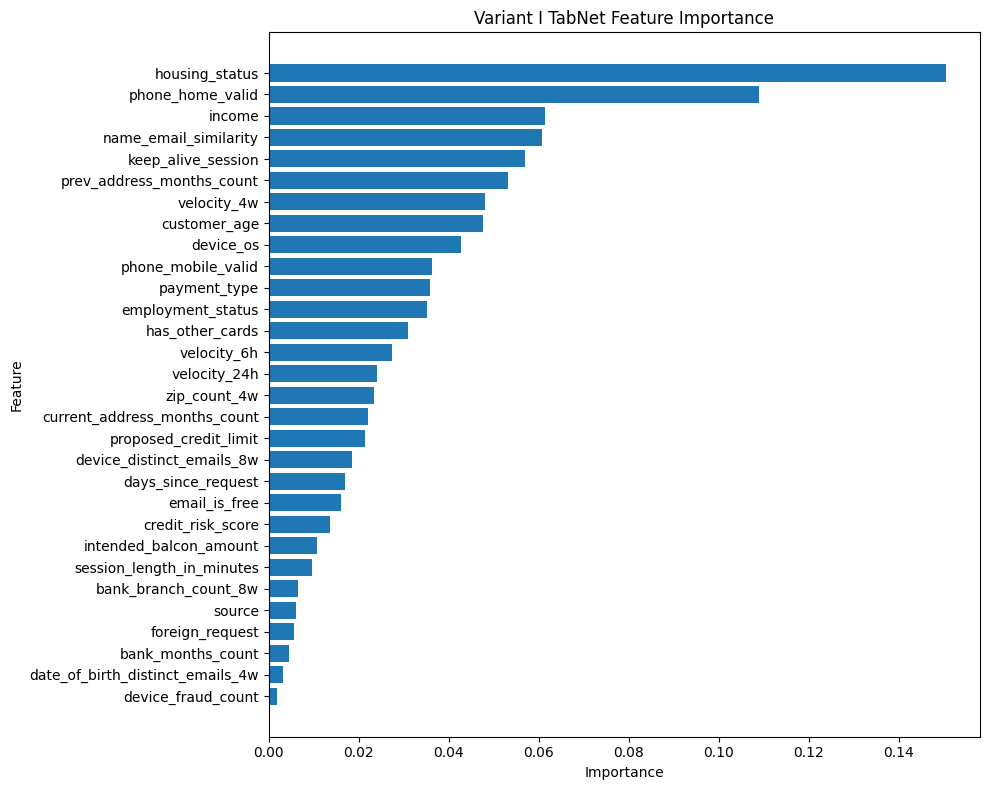

In [57]:
# ============================================================
# VARIANT I FEATURE IMPORTANCE
# ============================================================

importance_var1 = pd.DataFrame({

    "Feature":feature_names,

    "Importance":
    tabnet_var1.feature_importances_

})

importance_var1 = importance_var1.sort_values(

    by="Importance",

    ascending=False

)

print("="*60)
print("VARIANT I FEATURE IMPORTANCE")
print("="*60)

display(importance_var1)

# ----------------------------------------

plt.figure(figsize=(10,8))

plt.barh(

    importance_var1["Feature"],

    importance_var1["Importance"]

)

plt.gca().invert_yaxis()

plt.title(
    "Variant I TabNet Feature Importance"
)

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.tight_layout()

plt.show()

In [63]:

# ============================================================
# TABNET PREDICTION PROBABILITIES
# ============================================================

tabnet_base_prob = tabnet_base.predict_proba(
    X_base_test_np
)[:, 1]

tabnet_var1_prob = tabnet_var1.predict_proba(
    X_var1_test_np
)[:, 1]

print("Base probabilities:", tabnet_base_prob.shape)
print("Variant I probabilities:", tabnet_var1_prob.shape)

Base probabilities: (20000,)
Variant I probabilities: (20000,)


In [64]:

# ============================================================
# TABNET CLASS PREDICTIONS
# ============================================================

threshold = 0.5

tabnet_base_pred = (
    tabnet_base_prob >= threshold
).astype(int)

tabnet_var1_pred = (
    tabnet_var1_prob >= threshold
).astype(int)

print("Base predicted frauds:",
      (tabnet_base_pred == 1).sum())

print("Variant I predicted frauds:",
      (tabnet_var1_pred == 1).sum())

Base predicted frauds: 4177
Variant I predicted frauds: 5056


In [65]:

# ============================================================
# VERIFY TEST SET ALIGNMENT
# ============================================================

print("BASE")
print("Raw test rows :", len(X_base_test_raw))
print("True labels   :", len(y_base_test_raw))
print("Predictions   :", len(tabnet_base_pred))

print("\nVARIANT I")
print("Raw test rows :", len(X_var1_test_raw))
print("True labels   :", len(y_var1_test_raw))
print("Predictions   :", len(tabnet_var1_pred))

BASE
Raw test rows : 20000
True labels   : 20000
Predictions   : 20000

VARIANT I
Raw test rows : 20000
True labels   : 20000
Predictions   : 20000


**TabNet Fairness by Age Group**

In [67]:


import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix


def calculate_tabnet_age_fairness(
    X_test_raw,
    y_test_raw,
    y_pred,
    dataset_name
):

    y_true = np.asarray(
        y_test_raw
    ).flatten()

    y_pred = np.asarray(
        y_pred
    ).flatten()

    # Real age values
    ages = X_test_raw[
        "customer_age"
    ].to_numpy()

    groups = {

        "Age < 50":
            ages < 50,

        "Age >= 50":
            ages >= 50
    }

    results = []

    print("\n" + "=" * 65)
    print(dataset_name)
    print("=" * 65)

    for group_name, mask in groups.items():

        group_y_true = y_true[mask]
        group_y_pred = y_pred[mask]

        tn, fp, fn, tp = confusion_matrix(
            group_y_true,
            group_y_pred,
            labels=[0, 1]
        ).ravel()

        # True Positive Rate / Recall
        tpr = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        # False Positive Rate
        fpr = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else 0
        )

        # Predicted fraud rate
        predicted_positive_rate = (
            group_y_pred.mean()
        )

        print(f"\n{group_name}")
        print("-" * 40)

        print(
            "Applications        :",
            len(group_y_true)
        )

        print(
            "Actual frauds       :",
            int(group_y_true.sum())
        )

        print(
            "Predicted frauds    :",
            int(group_y_pred.sum())
        )

        print("\nConfusion matrix values")

        print("TP :", tp)
        print("FN :", fn)
        print("FP :", fp)
        print("TN :", tn)

        print("\nFairness metrics")

        print(
            "TPR / Recall        :",
            round(tpr, 4)
        )

        print(
            "FPR                 :",
            round(fpr, 4)
        )

        print(
            "Predicted fraud rate:",
            round(
                predicted_positive_rate,
                4
            )
        )

        results.append({

            "Dataset":
                dataset_name,

            "Group":
                group_name,

            "Applications":
                len(group_y_true),

            "Actual_Frauds":
                int(
                    group_y_true.sum()
                ),

            "Predicted_Frauds":
                int(
                    group_y_pred.sum()
                ),

            "TPR":
                tpr,

            "FPR":
                fpr,

            "Predicted_Positive_Rate":
                predicted_positive_rate
        })

    return pd.DataFrame(results)

In [68]:

#run Base tabnet


# ============================================================
# BASE TABNET FAIRNESS
# ============================================================

base_tabnet_age_fairness = calculate_tabnet_age_fairness(
    X_base_test_raw,
    y_base_test_raw,
    tabnet_base_pred,
    "BASE TABNET"
)

base_tabnet_age_fairness


BASE TABNET

Age < 50
----------------------------------------
Applications        : 16386
Actual frauds       : 141
Predicted frauds    : 2785

Confusion matrix values
TP : 94
FN : 47
FP : 2691
TN : 13554

Fairness metrics
TPR / Recall        : 0.6667
FPR                 : 0.1657
Predicted fraud rate: 0.17

Age >= 50
----------------------------------------
Applications        : 3614
Actual frauds       : 80
Predicted frauds    : 1392

Confusion matrix values
TP : 66
FN : 14
FP : 1326
TN : 2208

Fairness metrics
TPR / Recall        : 0.825
FPR                 : 0.3752
Predicted fraud rate: 0.3852


,Dataset,Group,Applications,Actual_Frauds,Predicted_Frauds,TPR,FPR,Predicted_Positive_Rate
0,BASE TABNET,Age < 50,16386,141,2785,0.666667,0.165651,0.169962
1,BASE TABNET,Age >= 50,3614,80,1392,0.825000,0.375212,0.385169


In [69]:

#run varinat tabnet


# ============================================================
# VARIANT I TABNET FAIRNESS
# ============================================================

variant1_tabnet_age_fairness = calculate_tabnet_age_fairness(
    X_var1_test_raw,
    y_var1_test_raw,
    tabnet_var1_pred,
    "VARIANT I TABNET"
)

variant1_tabnet_age_fairness


VARIANT I TABNET

Age < 50
----------------------------------------
Applications        : 17830
Actual frauds       : 198
Predicted frauds    : 4348

Confusion matrix values
TP : 149
FN : 49
FP : 4199
TN : 13433

Fairness metrics
TPR / Recall        : 0.7525
FPR                 : 0.2381
Predicted fraud rate: 0.2439

Age >= 50
----------------------------------------
Applications        : 2170
Actual frauds       : 23
Predicted frauds    : 708

Confusion matrix values
TP : 18
FN : 5
FP : 690
TN : 1457

Fairness metrics
TPR / Recall        : 0.7826
FPR                 : 0.3214
Predicted fraud rate: 0.3263


,Dataset,Group,Applications,Actual_Frauds,Predicted_Frauds,TPR,FPR,Predicted_Positive_Rate
0,VARIANT I TABNET,Age < 50,17830,198,4348,0.752525,0.238147,0.243859
1,VARIANT I TABNET,Age >= 50,2170,23,708,0.782609,0.321379,0.326267


In [70]:

# ============================================================
# CALCULATE FAIRNESS GAPS
# ============================================================

def calculate_gaps(df, model_name):

    younger = df[
        df["Group"] == "Age < 50"
    ].iloc[0]

    older = df[
        df["Group"] == "Age >= 50"
    ].iloc[0]

    tpr_gap = abs(
        younger["TPR"]
        -
        older["TPR"]
    )

    fpr_gap = abs(
        younger["FPR"]
        -
        older["FPR"]
    )

    prediction_gap = abs(
        younger["Predicted_Positive_Rate"]
        -
        older["Predicted_Positive_Rate"]
    )

    return {
        "Model": model_name,
        "TPR_Gap": tpr_gap,
        "FPR_Gap": fpr_gap,
        "Prediction_Rate_Gap": prediction_gap
    }


tabnet_gap_results = pd.DataFrame([

    calculate_gaps(
        base_tabnet_age_fairness,
        "Base TabNet"
    ),

    calculate_gaps(
        variant1_tabnet_age_fairness,
        "Variant I TabNet"
    )
])

tabnet_gap_results

,Model,TPR_Gap,FPR_Gap,Prediction_Rate_Gap
0,Base TabNet,0.158333,0.209561,0.215207
1,Variant I TabNet,0.030083,0.083232,0.082409


**TabNet Explainability by Age Group**

In [71]:

# ============================================================
# TABNET EXPLAINABILITY BY AGE GROUP
# ============================================================

import numpy as np
import pandas as pd

def tabnet_explain_by_age_group(
    model,
    X_test_np,
    X_test_raw,
    feature_names,
    dataset_name
):
    
    print("\n" + "=" * 70)
    print(dataset_name)
    print("=" * 70)

    ages = X_test_raw["customer_age"].to_numpy()

    groups = {
        "Age < 50": ages < 50,
        "Age >= 50": ages >= 50
    }

    results = {}

    for group_name, mask in groups.items():

        indices = np.where(mask)[0]

        X_group = X_test_np[indices]

        # TabNet explanation matrix
        explain_matrix, masks = model.explain(X_group)

        # Mean importance across all rows in this age group
        mean_importance = explain_matrix.mean(axis=0)

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Mean_Importance": mean_importance
        }).sort_values(
            "Mean_Importance",
            ascending=False
        ).reset_index(drop=True)

        print("\n" + group_name)
        print("-" * 50)
        print("Applications analysed:", len(indices))

        results[group_name] = importance_df

    return results

In [72]:

# ============================================================
# BASE TABNET EXPLAINABILITY
# ============================================================

base_tabnet_explain = tabnet_explain_by_age_group(
    model=tabnet_base,
    X_test_np=X_base_test_np,
    X_test_raw=X_base_test_raw,
    feature_names=feature_names,
    dataset_name="BASE TABNET"
)

print("\nBASE TABNET - AGE <50")
display(base_tabnet_explain["Age < 50"].head(15))

print("\nBASE TABNET - AGE >=50")
display(base_tabnet_explain["Age >= 50"].head(15))


BASE TABNET

Age < 50
--------------------------------------------------
Applications analysed: 16386

Age >= 50
--------------------------------------------------
Applications analysed: 3614

BASE TABNET - AGE <50


,Feature,Mean_Importance
0,keep_alive_session,2.257673
1,housing_status,2.104383
2,payment_type,1.437033
3,customer_age,1.423305
4,phone_home_valid,1.198687
5,income,1.129088
6,has_other_cards,1.013468
7,velocity_24h,0.975545
8,intended_balcon_amount,0.951909
9,device_os,0.745478



BASE TABNET - AGE >=50


,Feature,Mean_Importance
0,phone_home_valid,1.526447
1,housing_status,1.506103
2,has_other_cards,1.287241
3,income,1.214930
4,customer_age,1.197615
5,intended_balcon_amount,1.022514
6,velocity_6h,1.012903
7,payment_type,0.996235
8,device_os,0.979554
9,device_fraud_count,0.748673


In [73]:

# ============================================================
# VARIANT I TABNET EXPLAINABILITY
# ============================================================

variant1_tabnet_explain = tabnet_explain_by_age_group(
    model=tabnet_var1,
    X_test_np=X_var1_test_np,
    X_test_raw=X_var1_test_raw,
    feature_names=feature_names,
    dataset_name="VARIANT I TABNET"
)

print("\nVARIANT I TABNET - AGE <50")
display(variant1_tabnet_explain["Age < 50"].head(15))

print("\nVARIANT I TABNET - AGE >=50")
display(variant1_tabnet_explain["Age >= 50"].head(15))


VARIANT I TABNET

Age < 50
--------------------------------------------------
Applications analysed: 17830

Age >= 50
--------------------------------------------------
Applications analysed: 2170

VARIANT I TABNET - AGE <50


,Feature,Mean_Importance
0,housing_status,2.637778
1,phone_home_valid,1.864520
2,income,1.106101
3,name_email_similarity,1.029619
4,keep_alive_session,1.013220
5,prev_address_months_count,0.924335
6,velocity_4w,0.815216
7,customer_age,0.772035
8,device_os,0.748803
9,phone_mobile_valid,0.655691



VARIANT I TABNET - AGE >=50


,Feature,Mean_Importance
0,housing_status,2.593106
1,phone_home_valid,2.388424
2,payment_type,1.337402
3,customer_age,1.319984
4,name_email_similarity,1.177513
5,velocity_4w,1.107983
6,prev_address_months_count,1.101168
7,employment_status,1.032546
8,keep_alive_session,0.901430
9,velocity_6h,0.864308


**Protected Attribute Importance Comparison**

In [74]:

protected = [
    "customer_age",
    "employment_status",
    "income"
]

def compare_tabnet_protected(explain_result, dataset_name):

    younger = explain_result["Age < 50"].set_index("Feature")
    older = explain_result["Age >= 50"].set_index("Feature")

    comparison = pd.DataFrame({
        "Feature": protected,
        "Age_less_50": [
            younger.loc[f, "Mean_Importance"]
            for f in protected
        ],
        "Age_50_plus": [
            older.loc[f, "Mean_Importance"]
            for f in protected
        ]
    })

    comparison["Difference"] = (
        comparison["Age_50_plus"]
        -
        comparison["Age_less_50"]
    )

    comparison["Dataset"] = dataset_name

    return comparison


base_tabnet_protected = compare_tabnet_protected(
    base_tabnet_explain,
    "Base"
)

variant1_tabnet_protected = compare_tabnet_protected(
    variant1_tabnet_explain,
    "Variant I"
)

print("BASE TABNET - PROTECTED ATTRIBUTES")
display(base_tabnet_protected)

print("\nVARIANT I TABNET - PROTECTED ATTRIBUTES")
display(variant1_tabnet_protected)

BASE TABNET - PROTECTED ATTRIBUTES


,Feature,Age_less_50,Age_50_plus,Difference,Dataset
0,customer_age,1.423305,1.197615,-0.225690,Base
1,employment_status,0.101034,0.111471,0.010437,Base
2,income,1.129088,1.214930,0.085842,Base



VARIANT I TABNET - PROTECTED ATTRIBUTES


,Feature,Age_less_50,Age_50_plus,Difference,Dataset
0,customer_age,0.772035,1.319984,0.547949,Variant I
1,employment_status,0.557555,1.032546,0.474990,Variant I
2,income,1.106101,0.780697,-0.325404,Variant I


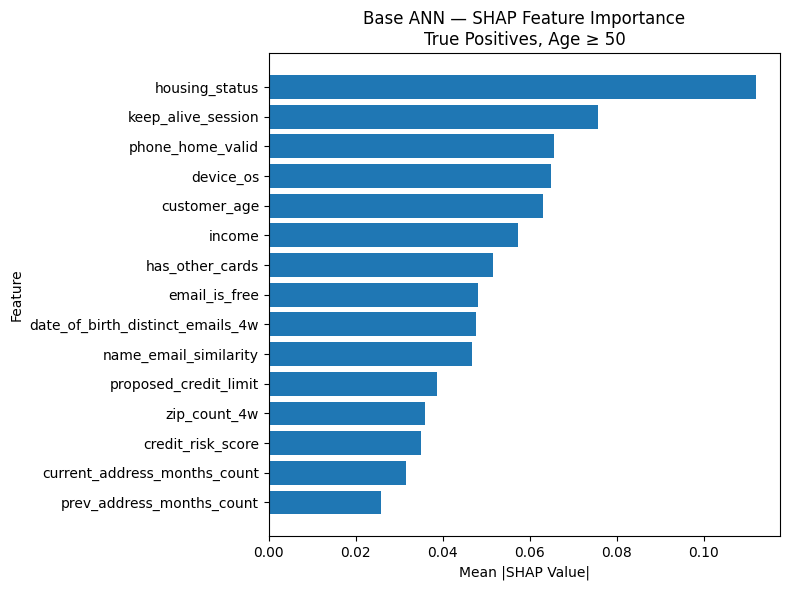

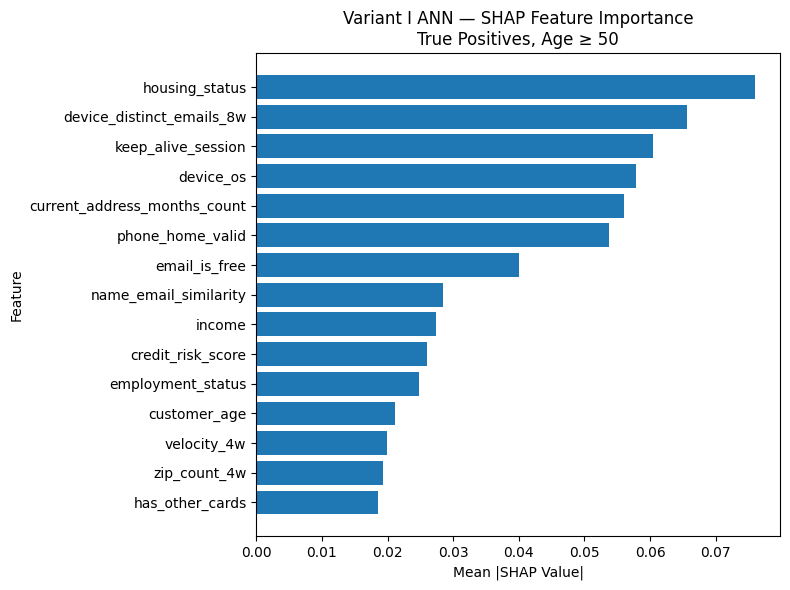

In [75]:
# ============================================================
# SHAP BAR PLOTS — AGE >= 50 TRUE POSITIVES
# BASE vs VARIANT I
# ============================================================

import matplotlib.pyplot as plt

# Get already-computed subgroup importance tables
base_older_tp = (
    base_age_shap["TP_50plus"]
    .head(15)
    .sort_values("Mean_ABS_SHAP", ascending=True)
)

var1_older_tp = (
    variant1_age_shap["TP_50plus"]
    .head(15)
    .sort_values("Mean_ABS_SHAP", ascending=True)
)

# ------------------------------------------------------------
# BASE
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.barh(
    base_older_tp["Feature"],
    base_older_tp["Mean_ABS_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")

plt.title(
    "Base ANN — SHAP Feature Importance\n"
    "True Positives, Age ≥ 50"
)

plt.tight_layout()

plt.savefig(
    "shap_base_age50plus_tp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# VARIANT I
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.barh(
    var1_older_tp["Feature"],
    var1_older_tp["Mean_ABS_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")

plt.title(
    "Variant I ANN — SHAP Feature Importance\n"
    "True Positives, Age ≥ 50"
)

plt.tight_layout()

plt.savefig(
    "shap_variant1_age50plus_tp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [77]:
print("BASE — Age >=50 — TP")
print(base_age_shap["TP_50plus"].head(15).to_string(index=False))

print("\nVARIANT I — Age >=50 — TP")
print(variant1_age_shap["TP_50plus"].head(15).to_string(index=False))

BASE — Age >=50 — TP
                         Feature  Mean_ABS_SHAP
                  housing_status       0.111902
              keep_alive_session       0.075557
                phone_home_valid       0.065454
                       device_os       0.064919
                    customer_age       0.063056
                          income       0.057189
                 has_other_cards       0.051497
                   email_is_free       0.048013
date_of_birth_distinct_emails_4w       0.047738
           name_email_similarity       0.046808
           proposed_credit_limit       0.038675
                    zip_count_4w       0.035862
               credit_risk_score       0.034916
    current_address_months_count       0.031603
       prev_address_months_count       0.025780

VARIANT I — Age >=50 — TP
                     Feature  Mean_ABS_SHAP
              housing_status       0.075998
   device_distinct_emails_8w       0.065693
          keep_alive_session       0.060481
        

In [78]:
print(
    base_age_shap["TP_50plus"]
    .reset_index(drop=True)
    .query("Feature == 'customer_age'")
)

print(
    variant1_age_shap["TP_50plus"]
    .reset_index(drop=True)
    .query("Feature == 'customer_age'")
)

        Feature  Mean_ABS_SHAP
4  customer_age       0.063056
         Feature  Mean_ABS_SHAP
11  customer_age         0.0212


In [79]:
print("BASE — Age >=50 — FP")
print(base_age_shap["FP_50plus"].head(15).to_string(index=False))

print("\nVARIANT I — Age >=50 — FP")
print(variant1_age_shap["FP_50plus"].head(15).to_string(index=False))

BASE — Age >=50 — FP
                         Feature  Mean_ABS_SHAP
                  housing_status       0.098058
              keep_alive_session       0.074714
                    customer_age       0.065866
                phone_home_valid       0.064512
                 has_other_cards       0.057509
                       device_os       0.056162
                          income       0.052990
                   email_is_free       0.048024
date_of_birth_distinct_emails_4w       0.044909
           proposed_credit_limit       0.043873
                    zip_count_4w       0.043367
           name_email_similarity       0.040011
               credit_risk_score       0.032391
    current_address_months_count       0.030116
       prev_address_months_count       0.026711

VARIANT I — Age >=50 — FP
                     Feature  Mean_ABS_SHAP
              housing_status       0.099423
            phone_home_valid       0.061777
current_address_months_count       0.061177
        

# Save Models

In [59]:
# Save models

tabnet_base.save_model("tabnet_base")

tabnet_var1.save_model("tabnet_variant1")

# Save feature importance

importance.to_csv(
    "tabnet_base_feature_importance.csv",
    index=False
)

comparison.to_csv(
    "tabnet_comparison.csv",
    index=False
)

print("Everything saved successfully.")

Successfully saved model at tabnet_base.zip
Successfully saved model at tabnet_variant1.zip
Everything saved successfully.


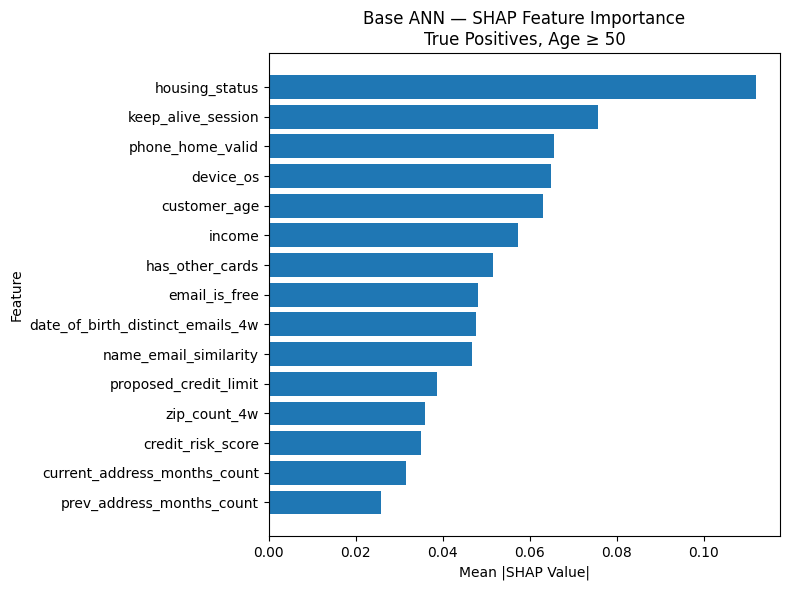

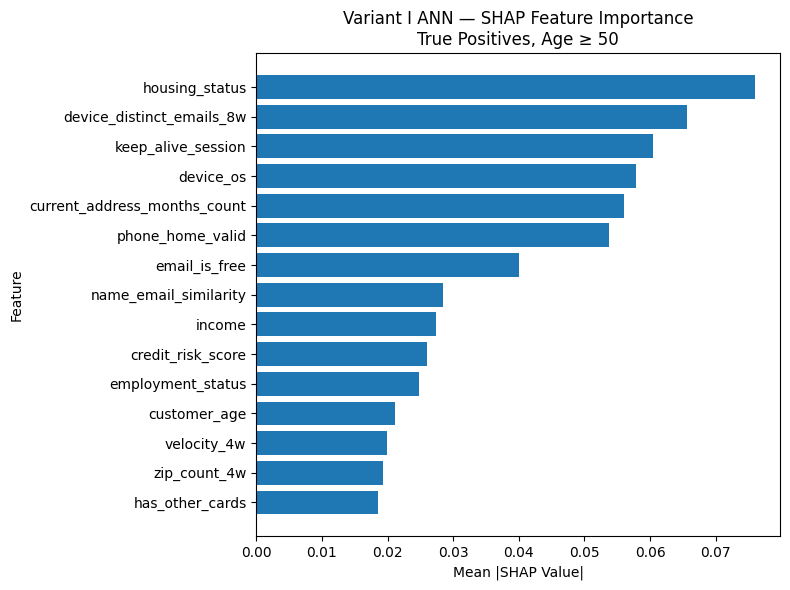

In [76]:
# ============================================================
# SHAP BAR PLOTS — AGE >= 50 TRUE POSITIVES
# BASE vs VARIANT I
# ============================================================

import matplotlib.pyplot as plt

# Get already-computed subgroup importance tables
base_older_tp = (
    base_age_shap["TP_50plus"]
    .head(15)
    .sort_values("Mean_ABS_SHAP", ascending=True)
)

var1_older_tp = (
    variant1_age_shap["TP_50plus"]
    .head(15)
    .sort_values("Mean_ABS_SHAP", ascending=True)
)

# ------------------------------------------------------------
# BASE
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.barh(
    base_older_tp["Feature"],
    base_older_tp["Mean_ABS_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")

plt.title(
    "Base ANN — SHAP Feature Importance\n"
    "True Positives, Age ≥ 50"
)

plt.tight_layout()

plt.savefig(
    "shap_base_age50plus_tp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# VARIANT I
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.barh(
    var1_older_tp["Feature"],
    var1_older_tp["Mean_ABS_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")

plt.title(
    "Variant I ANN — SHAP Feature Importance\n"
    "True Positives, Age ≥ 50"
)

plt.tight_layout()

plt.savefig(
    "shap_variant1_age50plus_tp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Building Agent

In [60]:
from typing import TypedDict, List, Dict, Any

class FRIAState(TypedDict):
    raw_data: List[Dict]        # input: your SHAP top-3 features per alert
    protected_attributes: List[str]   # ['customer_age', 'employment_status', 'income']
    extracted: List[Dict]       # output of Agent 1
    scored: List[Dict]          # output of Agent 2
    report: Dict                # output of Agent 3

In [76]:
import pandas as pd

# This is the file you already saved earlier
top_features_df_base = pd.read_csv('top_features_base.csv')

print(top_features_df_base.head())
print("Total alerts:", len(top_features_df_base))

   alert_id   top_feature_1                     top_feature_2  \
0         0    customer_age                    housing_status   
1         1  housing_status  date_of_birth_distinct_emails_4w   
2         2  housing_status                         device_os   
3         3  housing_status                keep_alive_session   
4         4  housing_status  date_of_birth_distinct_emails_4w   

        top_feature_3  protected_attr_in_top3  protected_attr_is_top  
0           device_os                    True                   True  
1              income                    True                  False  
2  keep_alive_session                   False                  False  
3           device_os                   False                  False  
4           device_os                   False                  False  
Total alerts: 50


In [62]:
import os
print("Current working directory:", os.getcwd())
print("\nFiles in this folder:")
for f in os.listdir():
    print(" ", f)

Current working directory: /Users/aishwaryagowda/Documents/Thesis/notebook

Files in this folder:
  tabnet_base_feature_importance.csv
  tabnet_comparison.csv
  .DS_Store
  employment_distribution.png
  anaconda_projects
  tabnet_base.zip
  y_var1_pred_prob.npy
  class_distribution.png
  y_var1_pred.npy
  Base.csv
  age_distribution.png
  ANN_results
  dataset_part.ipynb
  age_fraud_line_comparison.png
  ann_model_variant1.pt
  tabnet_variant1.zip
  age_bias_comparison.png
  ann_training_loss_comparison.png
  .ipynb_checkpoints
  income_distribution.png
  y_base_pred.npy
  class_imbalance_pie.png
  Variant_1.csv
  ann_model_base.pt
  y_base_pred_prob.npy
  shap_values_base.npy
  shap_values_variant1.npy


In [63]:
import subprocess
result = subprocess.run(['find', os.path.expanduser('~'), '-name', 'top_features_base.csv'], 
                        capture_output=True, text=True, timeout=30)
print(result.stdout if result.stdout else "File not found anywhere in home directory")

File not found anywhere in home directory


In [64]:
import pandas as pd

# Quick read of just the columns, not the full data
temp_df = pd.read_csv('Base.csv', nrows=1)
feature_names = temp_df.drop(columns=['fraud_bool', 'month']).columns.tolist()

print("Feature names reconstructed:", len(feature_names))
print(feature_names)

Feature names reconstructed: 30
['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'employment_status', 'credit_risk_score', 'email_is_free', 'housing_status', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source', 'session_length_in_minutes', 'device_os', 'keep_alive_session', 'device_distinct_emails_8w', 'device_fraud_count']


In [65]:
protected_attributes = ['customer_age', 'employment_status', 'income']
print("Protected attributes:", protected_attributes)

Protected attributes: ['customer_age', 'employment_status', 'income']


In [66]:
import numpy as np

shap_values_base = np.load('shap_values_base.npy')
shap_values_var1 = np.load('shap_values_variant1.npy')

print("SHAP Base shape:", shap_values_base.shape)
print("SHAP Variant I shape:", shap_values_var1.shape)
print("Expected number of features:", len(feature_names))

SHAP Base shape: (50, 30)
SHAP Variant I shape: (50, 30)
Expected number of features: 30


In [78]:
import numpy as np
import pandas as pd

# Load SHAP values
shap_values_base = np.load('shap_values_base.npy')

print("SHAP Base loaded successfully")
print("Shape:", shap_values_base.shape)

SHAP Base loaded successfully
Shape: (50, 30)


In [80]:
# Define the shared state for XAI-based risk assessment

from typing import TypedDict, List, Dict

class XAIRiskState(TypedDict):
    raw_data: List[Dict]
    protected_attributes: List[str]
    extracted: List[Dict]
    scored: List[Dict]
    report: Dict

In [81]:
# ============================================================
# DEFINE THE 3 XAI-BASED RISK ASSESSMENT AGENTS
# ============================================================


# ------------------------------------------------------------
# AGENT 1 - EXPLANATION EXTRACTOR
# ------------------------------------------------------------

def explanation_extractor_agent(state: XAIRiskState) -> XAIRiskState:
    
    print("Agent 1 (Explanation Extractor) is running...")
    
    extracted_list = []

    for row in state['raw_data']:
        
        extracted_list.append({
            'alert_id': row['alert_id'],
            'top_feature_1': row['top_feature_1'],
            'top_feature_2': row['top_feature_2'],
            'top_feature_3': row['top_feature_3']
        })

    print(f"Agent 1 processed {len(extracted_list)} alerts")

    state['extracted'] = extracted_list
    
    return state



# ------------------------------------------------------------
# AGENT 2 - XAI RISK SCREENER
# ------------------------------------------------------------

def xai_risk_scorer_agent(state: XAIRiskState) -> XAIRiskState:
    
    print("Agent 2 (XAI Risk Screener) is running...")
    
    protected = state['protected_attributes']
    
    scored_list = []

    for item in state['extracted']:

        top3 = [
            item['top_feature_1'],
            item['top_feature_2'],
            item['top_feature_3']
        ]

        # Check protected attribute prominence
        protected_is_top = (
            item['top_feature_1'] in protected
        )

        protected_in_top3 = any(
            feature in protected
            for feature in top3
        )

        # ----------------------------------------------------
        # XAI concern classification
        #
        # HIGH:
        # A protected attribute is the most influential feature.
        #
        # MODERATE:
        # A protected attribute appears in the top 3 but
        # is not ranked first.
        #
        # LOWER:
        # No protected attribute appears in the top 3.
        # ----------------------------------------------------

        if protected_is_top:
            
            xai_concern_level = "HIGH"

            reason = (
                "A protected attribute is ranked as the most "
                "influential feature in this explanation."
            )

        elif protected_in_top3:
            
            xai_concern_level = "MODERATE"

            reason = (
                "A protected attribute appears among the three "
                "most influential features in this explanation."
            )

        else:
            
            xai_concern_level = "LOWER"

            reason = (
                "No protected attribute appears among the three "
                "most influential features in this explanation."
            )

        scored_list.append({
            'alert_id': item['alert_id'],

            'xai_concern_level':
                xai_concern_level,

            'reason':
                reason,

            'protected_attr_in_top3':
                protected_in_top3,

            'protected_attr_is_top':
                protected_is_top,

            'top_feature_1':
                item['top_feature_1'],

            'top_feature_2':
                item['top_feature_2'],

            'top_feature_3':
                item['top_feature_3']
        })

    print(
        f"Agent 2 assessed {len(scored_list)} alerts"
    )

    state['scored'] = scored_list
    
    return state



# ------------------------------------------------------------
# AGENT 3 - REPORT GENERATOR
# ------------------------------------------------------------

def report_generator_agent(state: XAIRiskState) -> XAIRiskState:
    
    print("Agent 3 (Report Generator) is running...")
    
    scores = state['scored']
    
    total = len(scores)

    # Count concern levels
    high_count = sum(
        1 for s in scores
        if s['xai_concern_level'] == "HIGH"
    )

    moderate_count = sum(
        1 for s in scores
        if s['xai_concern_level'] == "MODERATE"
    )

    lower_count = sum(
        1 for s in scores
        if s['xai_concern_level'] == "LOWER"
    )

    # Protected attribute statistics
    protected_top3_pct = (
        sum(
            1 for s in scores
            if s['protected_attr_in_top3']
        )
        / total
        * 100
    )

    protected_top_pct = (
        sum(
            1 for s in scores
            if s['protected_attr_is_top']
        )
        / total
        * 100
    )

    # --------------------------------------------------------
    # Overall descriptive assessment
    #
    # IMPORTANT:
    # This is NOT a fairness verdict.
    # It summarises XAI-based protected-attribute prominence.
    # --------------------------------------------------------

    if high_count > 0:
        
        overall_assessment = (
            "XAI-BASED CONCERN IDENTIFIED"
        )

    elif moderate_count > 0:
        
        overall_assessment = (
            "MODERATE XAI-BASED CONCERN"
        )

    else:
        
        overall_assessment = (
            "LOWER XAI-BASED CONCERN"
        )

    report = {

        'total_alerts_evaluated':
            total,

        'high_concern_count':
            high_count,

        'moderate_concern_count':
            moderate_count,

        'lower_concern_count':
            lower_count,

        'high_concern_pct':
            round(high_count / total * 100, 1),

        'moderate_concern_pct':
            round(moderate_count / total * 100, 1),

        'lower_concern_pct':
            round(lower_count / total * 100, 1),

        'protected_attr_in_top3_pct':
            round(protected_top3_pct, 1),

        'protected_attr_is_top_pct':
            round(protected_top_pct, 1),

        'overall_xai_assessment':
            overall_assessment,

        'interpretation':
            (
                "This assessment reflects protected-attribute "
                "prominence within the model explanations. "
                "It is an XAI-based screening result and does "
                "not independently determine model fairness "
                "or FRIA compliance."
            )
    }

    print("Agent 3 generated the XAI risk report")

    state['report'] = report
    
    return state


print("All 3 XAI-based agent functions defined successfully")

All 3 XAI-based agent functions defined successfully


In [82]:
# ============================================================
# BUILD LANGGRAPH XAI RISK ASSESSMENT PIPELINE
# ============================================================

from langgraph.graph import StateGraph, END

workflow = StateGraph(XAIRiskState)

workflow.add_node(
    "extractor",
    explanation_extractor_agent
)

workflow.add_node(
    "xai_risk_screener",
    xai_risk_scorer_agent
)

workflow.add_node(
    "reporter",
    report_generator_agent
)

workflow.set_entry_point("extractor")

workflow.add_edge(
    "extractor",
    "xai_risk_screener"
)

workflow.add_edge(
    "xai_risk_screener",
    "reporter"
)

workflow.add_edge(
    "reporter",
    END
)

xai_risk_pipeline = workflow.compile()

print("LangGraph XAI risk assessment pipeline built successfully")

LangGraph XAI risk assessment pipeline built successfully


In [73]:
import sys
print(sys.executable)

/opt/anaconda3/envs/thesis_env/bin/python


In [74]:
import sys, subprocess
result = subprocess.run([sys.executable, '-m', 'pip', 'install', 'langgraph'], 
                        capture_output=True, text=True)
print(result.stdout[-2000:])
print("---ERRORS---")
print(result.stderr[-1000:])

_x86_64.macosx_11_0_arm64.macosx_10_12_universal2.whl (378 kB)
Using cached sniffio-1.3.1-py3-none-any.whl (10 kB)
Using cached typing_inspection-0.4.2-py3-none-any.whl (14 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/640.6 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 640.6/640.6 kB 7.3 MB/s  0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━ 15/22 [pydantic]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━ 16/22 [langsmith]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━ 16/22 [langsmith]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━ 17/22 [langchain-core]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━ 21/22 [langgraph]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22/22 [langgraph]


---ERRORS---



In [75]:
from langgraph.graph import StateGraph, END
print("StateGraph imported successfully")

StateGraph imported successfully


In [83]:
# ============================================================
# BUILD LANGGRAPH XAI-BASED RISK ASSESSMENT PIPELINE
# ============================================================

from langgraph.graph import StateGraph, END

workflow = StateGraph(XAIRiskState)

# Add the three agents
workflow.add_node("extractor", explanation_extractor_agent)
workflow.add_node("xai_risk_screener", xai_risk_scorer_agent)
workflow.add_node("reporter", report_generator_agent)

# Define workflow
workflow.set_entry_point("extractor")

workflow.add_edge("extractor", "xai_risk_screener")
workflow.add_edge("xai_risk_screener", "reporter")
workflow.add_edge("reporter", END)

# Compile pipeline
xai_risk_pipeline = workflow.compile()

print("LangGraph XAI-based risk assessment pipeline built successfully")

LangGraph XAI-based risk assessment pipeline built successfully


In [87]:
# ============================================================
# REGENERATE TOP FEATURES — VARIANT I
# ============================================================

import numpy as np
import pandas as pd

# Load Variant I SHAP values
shap_values_var1 = np.load('shap_values_variant1.npy')

print("Variant I SHAP values loaded:", shap_values_var1.shape)

# Convert SHAP values to DataFrame
shap_df_var1 = pd.DataFrame(
    shap_values_var1,
    columns=feature_names
)

top_features_var1 = []

for i in range(len(shap_df_var1)):

    row = shap_df_var1.iloc[i]

    # Three features with largest absolute SHAP values
    top3 = row.abs().nlargest(3)

    top_features_var1.append({
        'alert_id': i,

        'top_feature_1': top3.index[0],
        'top_feature_2': top3.index[1],
        'top_feature_3': top3.index[2],

        'protected_attr_in_top3':
            any(
                feature in top3.index
                for feature in protected_attributes
            ),

        'protected_attr_is_top':
            top3.index[0] in protected_attributes
    })


# Create DataFrame
top_features_df_var1 = pd.DataFrame(top_features_var1)

# Save
top_features_df_var1.to_csv(
    'top_features_var1.csv',
    index=False
)

print(
    "Regenerated Variant I top features. Total alerts:",
    len(top_features_df_var1)
)

print(
    "Protected attribute in top 3:",
    round(
        top_features_df_var1[
            'protected_attr_in_top3'
        ].mean() * 100,
        1
    ),
    "%"
)

print(
    "Protected attribute ranked #1:",
    round(
        top_features_df_var1[
            'protected_attr_is_top'
        ].mean() * 100,
        1
    ),
    "%"
)

Variant I SHAP values loaded: (50, 30)
Regenerated Variant I top features. Total alerts: 50
Protected attribute in top 3: 12.0 %
Protected attribute ranked #1: 0.0 %


In [88]:
# ============================================================
# RUN XAI-BASED RISK ASSESSMENT — SHAP / BASE DATASET
# ============================================================

initial_state_base = {
    'raw_data': top_features_df_base.to_dict('records'),
    'protected_attributes': protected_attributes,
    'extracted': [],
    'scored': [],
    'report': {}
}

# Run the XAI risk assessment pipeline
result_base = xai_risk_pipeline.invoke(initial_state_base)

# Display report
print("\n" + "="*60)
print("XAI-BASED RISK ASSESSMENT REPORT — SHAP / Base Dataset")
print("="*60)

for key, value in result_base['report'].items():
    print(f"{key}: {value}")

Agent 1 (Explanation Extractor) is running...
Agent 1 processed 50 alerts
Agent 2 (XAI Risk Screener) is running...
Agent 2 assessed 50 alerts
Agent 3 (Report Generator) is running...
Agent 3 generated the XAI risk report

XAI-BASED RISK ASSESSMENT REPORT — SHAP / Base Dataset
total_alerts_evaluated: 50
high_concern_count: 4
moderate_concern_count: 24
lower_concern_count: 22
high_concern_pct: 8.0
moderate_concern_pct: 48.0
lower_concern_pct: 44.0
protected_attr_in_top3_pct: 56.0
protected_attr_is_top_pct: 8.0
overall_xai_assessment: XAI-BASED CONCERN IDENTIFIED
interpretation: This assessment reflects protected-attribute prominence within the model explanations. It is an XAI-based screening result and does not independently determine model fairness or FRIA compliance.


In [89]:
# ============================================================
# RUN XAI-BASED RISK ASSESSMENT — SHAP / VARIANT I DATASET
# ============================================================

initial_state_var1 = {
    'raw_data': top_features_df_var1.to_dict('records'),
    'protected_attributes': protected_attributes,
    'extracted': [],
    'scored': [],
    'report': {}
}

# Run the XAI risk assessment pipeline
result_var1 = xai_risk_pipeline.invoke(initial_state_var1)

# Display report
print("\n" + "="*60)
print("XAI-BASED RISK ASSESSMENT REPORT — SHAP / Variant I Dataset")
print("="*60)

for key, value in result_var1['report'].items():
    print(f"{key}: {value}")

Agent 1 (Explanation Extractor) is running...
Agent 1 processed 50 alerts
Agent 2 (XAI Risk Screener) is running...
Agent 2 assessed 50 alerts
Agent 3 (Report Generator) is running...
Agent 3 generated the XAI risk report

XAI-BASED RISK ASSESSMENT REPORT — SHAP / Variant I Dataset
total_alerts_evaluated: 50
high_concern_count: 0
moderate_concern_count: 6
lower_concern_count: 44
high_concern_pct: 0.0
moderate_concern_pct: 12.0
lower_concern_pct: 88.0
protected_attr_in_top3_pct: 12.0
protected_attr_is_top_pct: 0.0
overall_xai_assessment: MODERATE XAI-BASED CONCERN
interpretation: This assessment reflects protected-attribute prominence within the model explanations. It is an XAI-based screening result and does not independently determine model fairness or FRIA compliance.


# Passing TabNet data to agentic pipeline

In [81]:
tabnet_base_fi = pd.read_csv('tabnet_base_feature_importance.csv')
print(tabnet_base_fi.head(10))
print("\nColumns:", tabnet_base_fi.columns.tolist())
print("Total rows:", len(tabnet_base_fi))

                  Feature  Importance
0          housing_status    0.101486
1      keep_alive_session    0.099210
2            customer_age    0.070914
3            payment_type    0.069944
4        phone_home_valid    0.065335
5                  income    0.059257
6         has_other_cards    0.054636
7  intended_balcon_amount    0.049660
8            velocity_24h    0.045607
9               device_os    0.040423

Columns: ['Feature', 'Importance']
Total rows: 30


In [82]:
tabnet_comparison = pd.read_csv('tabnet_comparison.csv')
print(tabnet_comparison.head(10))
print("\nColumns:", tabnet_comparison.columns.tolist())

                     Feature  Base_Importance  Variant1_Importance  Difference
0  prev_address_months_count         0.000428             0.053133    0.052704
1             housing_status         0.101486             0.150576    0.049091
2      name_email_similarity         0.016929             0.060666    0.043737
3           phone_home_valid         0.065335             0.108982    0.043647
4          employment_status         0.005256             0.035184    0.029928
5         phone_mobile_valid         0.008176             0.036395    0.028219
6                velocity_4w         0.023476             0.048036    0.024560
7         days_since_request         0.003261             0.016923    0.013662
8  session_length_in_minutes         0.002649             0.009674    0.007025
9      proposed_credit_limit         0.018608             0.021426    0.002818

Columns: ['Feature', 'Base_Importance', 'Variant1_Importance', 'Difference']


# Building Agentic pipeline for Variant_1 model-level explainantion

In [93]:
# ============================================================
# DEFINE STATE FOR MODEL-LEVEL XAI RISK ASSESSMENT
# ============================================================

from typing import TypedDict, List, Dict, Any

class ModelLevelXAIRiskState(TypedDict):
    importance_df: Any              # Feature/Importance dataframe
    protected_attributes: List[str]
    ranked: List[Dict]              # output of Agent 1
    scored: Dict                    # output of Agent 2
    report: Dict                    # output of Agent 3

print("ModelLevelXAIRiskState defined successfully")

ModelLevelXAIRiskState defined successfully


In [94]:
# ============================================================
# MODEL-LEVEL AGENT 1 — RANKING EXTRACTOR
# ============================================================

def model_level_extractor_agent(
    state: ModelLevelXAIRiskState
) -> ModelLevelXAIRiskState:

    print("Agent 1 (Model-Level Explanation Extractor) is running...")

    # Rank features from highest to lowest importance
    df = (
        state['importance_df']
        .sort_values('Importance', ascending=False)
        .reset_index(drop=True)
    )

    ranked = []

    for i, row in df.iterrows():
        ranked.append({
            'rank': i + 1,
            'feature': row['Feature'],
            'importance': row['Importance']
        })

    print(f"Agent 1 ranked {len(ranked)} features")

    state['ranked'] = ranked

    return state

In [95]:
# ============================================================
# MODEL-LEVEL AGENT 2 — XAI RISK SCREENER
# ============================================================

def model_level_xai_risk_scorer_agent(
    state: ModelLevelXAIRiskState
) -> ModelLevelXAIRiskState:

    print("Agent 2 (Model-Level XAI Risk Screener) is running...")

    protected = state['protected_attributes']
    ranked = state['ranked']

    # Study-specific top-k screening window
    top_n = 5

    top_features = ranked[:top_n]

    top_feature_names = [
        f['feature']
        for f in top_features
    ]

    # Protected attributes appearing in top 5
    protected_in_top5 = [
        f for f in top_feature_names
        if f in protected
    ]

    protected_count_in_top5 = len(
        protected_in_top5
    )

    # --------------------------------------------------------
    # Protected-attribute importance share
    #
    # Used only as descriptive XAI evidence.
    # It is NOT converted into a fairness score.
    # --------------------------------------------------------

    protected_weight = sum(
        f['importance']
        for f in top_features
        if f['feature'] in protected
    )

    total_top5_weight = sum(
        f['importance']
        for f in top_features
    )

    protected_weight_share = (
        protected_weight / total_top5_weight * 100
        if total_top5_weight > 0
        else 0
    )

    # Check whether rank #1 is protected
    is_top1_protected = (
        top_feature_names[0] in protected
    )

    # --------------------------------------------------------
    # XAI CONCERN CLASSIFICATION
    #
    # HIGH:
    # Protected attribute is ranked #1.
    #
    # MODERATE:
    # Protected attribute occurs within the top 5,
    # but is not ranked first.
    #
    # LOWER:
    # No protected attribute occurs within the top 5.
    #
    # These are XAI screening categories,
    # NOT fairness or FRIA compliance verdicts.
    # --------------------------------------------------------

    if is_top1_protected:

        xai_concern_level = "HIGH"

        reason = (
            "A protected attribute is the highest-ranked "
            "feature in the model-level explanation."
        )

    elif protected_count_in_top5 > 0:

        xai_concern_level = "MODERATE"

        reason = (
            "One or more protected attributes appear among "
            "the five most influential model features."
        )

    else:

        xai_concern_level = "LOWER"

        reason = (
            "No protected attribute appears among the five "
            "most influential model features."
        )

    scored = {

        'top_5_features':
            top_feature_names,

        'protected_attrs_in_top5':
            protected_in_top5,

        'protected_count_in_top5':
            protected_count_in_top5,

        'top1_is_protected':
            is_top1_protected,

        'protected_weight_share_pct':
            round(protected_weight_share, 1),

        'xai_concern_level':
            xai_concern_level,

        'reason':
            reason
    }

    print("Agent 2 completed model-level XAI screening")

    state['scored'] = scored

    return state

In [96]:
# ============================================================
# MODEL-LEVEL AGENT 3 — XAI RISK REPORT GENERATOR
# ============================================================

def model_level_report_agent(
    state: ModelLevelXAIRiskState
) -> ModelLevelXAIRiskState:

    print("Agent 3 (Model-Level XAI Report Generator) is running...")

    s = state['scored']

    # Overall XAI-based assessment
    if s['xai_concern_level'] == "HIGH":
        overall_assessment = "HIGH XAI-BASED CONCERN"

    elif s['xai_concern_level'] == "MODERATE":
        overall_assessment = "MODERATE XAI-BASED CONCERN"

    else:
        overall_assessment = "LOWER XAI-BASED CONCERN"

    report = {
        'evaluation_type':
            'model-level XAI assessment using TabNet feature importance',

        'top_5_features':
            s['top_5_features'],

        'protected_attrs_in_top5':
            s['protected_attrs_in_top5'],

        'protected_weight_share_pct':
            s['protected_weight_share_pct'],

        'xai_concern_level':
            s['xai_concern_level'],

        'reason':
            s['reason'],

        'overall_xai_assessment':
            overall_assessment,

        'interpretation': (
            "This result reflects the prominence of protected attributes "
            "within the TabNet model explanation. It is an XAI-based "
            "screening result and does not independently determine "
            "model fairness or FRIA compliance."
        )
    }

    print("Agent 3 generated the model-level XAI risk report")

    state['report'] = report

    return state

In [97]:
# ============================================================
# BUILD MODEL-LEVEL XAI RISK ASSESSMENT PIPELINE
# ============================================================

model_level_workflow = StateGraph(ModelLevelXAIRiskState)

model_level_workflow.add_node(
    "extractor",
    model_level_extractor_agent
)

model_level_workflow.add_node(
    "xai_risk_screener",
    model_level_xai_risk_scorer_agent
)

model_level_workflow.add_node(
    "reporter",
    model_level_report_agent
)

model_level_workflow.set_entry_point("extractor")

model_level_workflow.add_edge(
    "extractor",
    "xai_risk_screener"
)

model_level_workflow.add_edge(
    "xai_risk_screener",
    "reporter"
)

model_level_workflow.add_edge(
    "reporter",
    END
)

model_level_xai_pipeline = model_level_workflow.compile()

print("Model-level XAI risk assessment pipeline built successfully")

Model-level XAI risk assessment pipeline built successfully


In [99]:
import pandas as pd

# Load saved TabNet Base feature importance
tabnet_base_fi = pd.read_csv('tabnet_base_feature_importance.csv')

print("TabNet Base feature importance loaded successfully")
print("Shape:", tabnet_base_fi.shape)
print("\nColumns:", tabnet_base_fi.columns.tolist())

display(tabnet_base_fi.head(10))

TabNet Base feature importance loaded successfully
Shape: (30, 2)

Columns: ['Feature', 'Importance']


,Feature,Importance
0,housing_status,0.101486
1,keep_alive_session,0.099210
2,customer_age,0.070914
3,payment_type,0.069944
4,phone_home_valid,0.065335
5,income,0.059257
6,has_other_cards,0.054636
7,intended_balcon_amount,0.049660
8,velocity_24h,0.045607
9,device_os,0.040423


In [100]:
# ============================================================
# RUN MODEL-LEVEL XAI RISK ASSESSMENT — TABNET / BASE
# ============================================================

tabnet_base_state = {
    'importance_df': tabnet_base_fi,
    'protected_attributes': protected_attributes,
    'ranked': [],
    'scored': {},
    'report': {}
}

tabnet_base_result = model_level_xai_pipeline.invoke(
    tabnet_base_state
)

print("\n" + "="*60)
print("XAI-BASED RISK ASSESSMENT REPORT — TabNet / Base Dataset")
print("="*60)

for key, value in tabnet_base_result['report'].items():
    print(f"{key}: {value}")

Agent 1 (Model-Level Explanation Extractor) is running...
Agent 1 ranked 30 features
Agent 2 (Model-Level XAI Risk Screener) is running...
Agent 2 completed model-level XAI screening
Agent 3 (Model-Level XAI Report Generator) is running...
Agent 3 generated the model-level XAI risk report

XAI-BASED RISK ASSESSMENT REPORT — TabNet / Base Dataset
evaluation_type: model-level XAI assessment using TabNet feature importance
top_5_features: ['housing_status', 'keep_alive_session', 'customer_age', 'payment_type', 'phone_home_valid']
protected_attrs_in_top5: ['customer_age']
protected_weight_share_pct: 17.4
xai_concern_level: MODERATE
reason: One or more protected attributes appear among the five most influential model features.
overall_xai_assessment: MODERATE XAI-BASED CONCERN
interpretation: This result reflects the prominence of protected attributes within the TabNet model explanation. It is an XAI-based screening result and does not independently determine model fairness or FRIA complian

In [103]:
# ============================================================
# RUN MODEL-LEVEL XAI RISK ASSESSMENT — TABNET / VARIANT I
# ============================================================

# Prepare Variant I feature importance dataframe
tabnet_var1_fi = tabnet_comparison[
    ['Feature', 'Variant1_Importance']
].rename(
    columns={'Variant1_Importance': 'Importance'}
)

tabnet_var1_state = {
    'importance_df': tabnet_var1_fi,
    'protected_attributes': protected_attributes,
    'ranked': [],
    'scored': {},
    'report': {}
}

# Run the model-level XAI pipeline
tabnet_var1_result = model_level_xai_pipeline.invoke(
    tabnet_var1_state
)

# Display report
print("\n" + "="*60)
print("XAI-BASED RISK ASSESSMENT REPORT — TabNet / Variant I Dataset")
print("="*60)

for key, value in tabnet_var1_result['report'].items():
    print(f"{key}: {value}")

Agent 1 (Model-Level Explanation Extractor) is running...
Agent 1 ranked 30 features
Agent 2 (Model-Level XAI Risk Screener) is running...
Agent 2 completed model-level XAI screening
Agent 3 (Model-Level XAI Report Generator) is running...
Agent 3 generated the model-level XAI risk report

XAI-BASED RISK ASSESSMENT REPORT — TabNet / Variant I Dataset
evaluation_type: model-level XAI assessment using TabNet feature importance
top_5_features: ['housing_status', 'phone_home_valid', 'income', 'name_email_similarity', 'keep_alive_session']
protected_attrs_in_top5: ['income']
protected_weight_share_pct: 14.0
xai_concern_level: MODERATE
reason: One or more protected attributes appear among the five most influential model features.
overall_xai_assessment: MODERATE XAI-BASED CONCERN
interpretation: This result reflects the prominence of protected attributes within the TabNet model explanation. It is an XAI-based screening result and does not independently determine model fairness or FRIA compli

# Generating the comparison chart

In [106]:
# ============================================================
# COMBINE FINAL XAI RISK ASSESSMENT RESULTS
# ============================================================

import pandas as pd

comparison_data = []

# ---------------- SHAP / Base ----------------
comparison_data.append({
    'Method': 'SHAP',
    'Dataset': 'Base',
    'Evaluation_Level': 'Prediction-level',
    'Protected_in_TopK_Pct':
        result_base['report']['protected_attr_in_top3_pct'],
    'Protected_Top1_Pct':
        result_base['report']['protected_attr_is_top_pct'],
    'XAI_Assessment':
        result_base['report']['overall_xai_assessment']
})

# ---------------- SHAP / Variant I ----------------
comparison_data.append({
    'Method': 'SHAP',
    'Dataset': 'Variant I',
    'Evaluation_Level': 'Prediction-level',
    'Protected_in_TopK_Pct':
        result_var1['report']['protected_attr_in_top3_pct'],
    'Protected_Top1_Pct':
        result_var1['report']['protected_attr_is_top_pct'],
    'XAI_Assessment':
        result_var1['report']['overall_xai_assessment']
})

# ---------------- TabNet / Base ----------------
comparison_data.append({
    'Method': 'TabNet',
    'Dataset': 'Base',
    'Evaluation_Level': 'Model-level',
    'Protected_in_TopK_Pct':
        tabnet_base_result['report']['protected_weight_share_pct'],
    'Protected_Top1_Pct': None,
    'XAI_Assessment':
        tabnet_base_result['report']['overall_xai_assessment']
})

# ---------------- TabNet / Variant I ----------------
comparison_data.append({
    'Method': 'TabNet',
    'Dataset': 'Variant I',
    'Evaluation_Level': 'Model-level',
    'Protected_in_TopK_Pct':
        tabnet_var1_result['report']['protected_weight_share_pct'],
    'Protected_Top1_Pct': None,
    'XAI_Assessment':
        tabnet_var1_result['report']['overall_xai_assessment']
})

xai_comparison_df = pd.DataFrame(comparison_data)

display(xai_comparison_df)

,Method,Dataset,Evaluation_Level,Protected_in_TopK_Pct,Protected_Top1_Pct,XAI_Assessment
0,SHAP,Base,Prediction-level,56.0,8.0,XAI-BASED CONCERN IDENTIFIED
1,SHAP,Variant I,Prediction-level,12.0,0.0,MODERATE XAI-BASED CONCERN
2,TabNet,Base,Model-level,17.4,NaN,MODERATE XAI-BASED CONCERN
3,TabNet,Variant I,Model-level,14.0,NaN,MODERATE XAI-BASED CONCERN


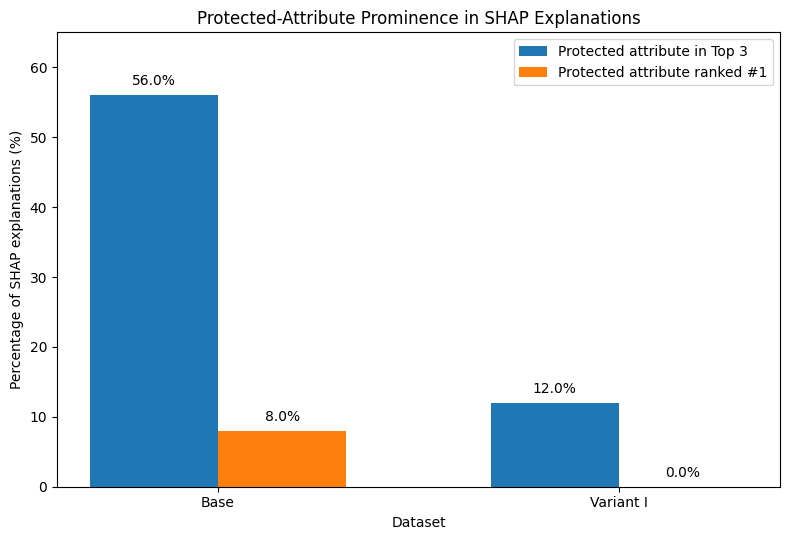

In [107]:
# ============================================================
# SHAP XAI RISK COMPARISON — BASE vs VARIANT I
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

datasets = ['Base', 'Variant I']

protected_top3 = [
    result_base['report']['protected_attr_in_top3_pct'],
    result_var1['report']['protected_attr_in_top3_pct']
]

protected_top1 = [
    result_base['report']['protected_attr_is_top_pct'],
    result_var1['report']['protected_attr_is_top_pct']
]

x = np.arange(len(datasets))
width = 0.32

fig, ax = plt.subplots(figsize=(8, 5.5))

bars1 = ax.bar(
    x - width/2,
    protected_top3,
    width,
    label='Protected attribute in Top 3'
)

bars2 = ax.bar(
    x + width/2,
    protected_top1,
    width,
    label='Protected attribute ranked #1'
)

ax.set_ylabel('Percentage of SHAP explanations (%)')
ax.set_xlabel('Dataset')
ax.set_title(
    'Protected-Attribute Prominence in SHAP Explanations'
)

ax.set_xticks(x)
ax.set_xticklabels(datasets)

ax.set_ylim(0, 65)
ax.legend()

# Add percentage labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f'{height:.1f}%',
            ha='center',
            va='bottom'
        )

plt.tight_layout()

plt.savefig(
    'shap_xai_protected_attribute_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


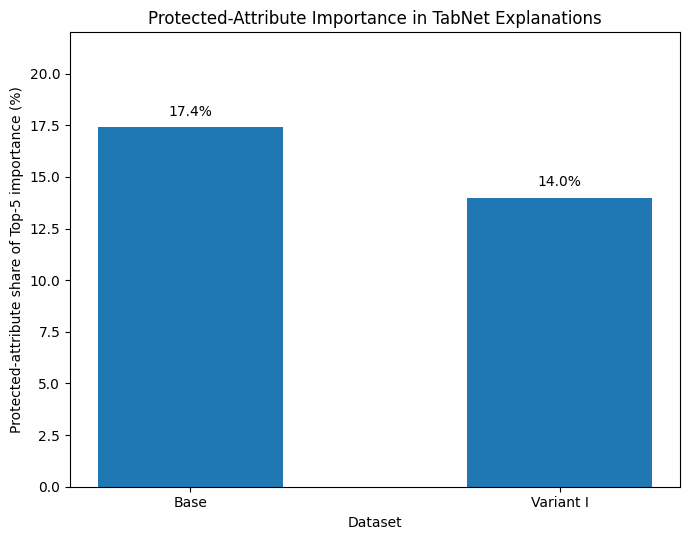

In [108]:
# ============================================================
# TABNET XAI RISK COMPARISON — BASE vs VARIANT I
# ============================================================

import matplotlib.pyplot as plt

datasets = ['Base', 'Variant I']

protected_weight_share = [
    tabnet_base_result['report']['protected_weight_share_pct'],
    tabnet_var1_result['report']['protected_weight_share_pct']
]

fig, ax = plt.subplots(figsize=(7, 5.5))

bars = ax.bar(
    datasets,
    protected_weight_share,
    width=0.5
)

ax.set_ylabel(
    'Protected-attribute share of Top-5 importance (%)'
)

ax.set_xlabel('Dataset')

ax.set_title(
    'Protected-Attribute Importance in TabNet Explanations'
)

ax.set_ylim(0, 22)

for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.4,
        f'{height:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.savefig(
    'tabnet_xai_protected_attribute_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()